# AtlasNLP Post-Audit Analysis — v2.2 (Foundation)

This notebook establishes the **post-audit source of truth** before the old paper plots are migrated.

It currently covers:

1. frozen v2.2 file loading and integrity assertions;
2. headline summary statistics for the 18,035 source records and 13,462 eligible records;
3. primary **explicit-only** vs. **explicit+inferred sensitivity** geography summaries;
4. the 400-record Stage-1 audit join and error-analysis diagnostics;
5. reproduction of the 100-record producer audit;
6. the corrected Gold → NLI → Core recovery path (425 → 377 → 372);
7. a first old-paper → rebuttal → v2.2 reconciliation table; and
8. an indexed migration plan for the old analysis notebooks.

The next section of this same notebook is intended to migrate the actual paper analyses/figures from `Analysis Exploration.ipynb` using these frozen denominators.

## 1. Setup

In [1]:
from pathlib import Path
import os, re, ast, json
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)

DATA_DIR = Path(os.environ.get("ATLASNLP_DATA_DIR", ".")).expanduser().resolve()
OUTPUT_DIR = Path(os.environ.get("ATLASNLP_OUTPUT_DIR", DATA_DIR / "post_audit_outputs_camera_ready_style")).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = []
for d in [DATA_DIR, Path.cwd(), Path("/mnt/data")]:
    d = d.resolve()
    if d not in SEARCH_DIRS:
        SEARCH_DIRS.append(d)

def resolve_file(canonical_name, required=True, extra_patterns=None):
    canonical = Path(canonical_name)
    patterns = [canonical_name, f"{canonical.stem}*{canonical.suffix}"]
    if extra_patterns:
        patterns.extend(extra_patterns)
    hits = []
    seen = set()
    for base in SEARCH_DIRS:
        for pat in patterns:
            for p in sorted(base.glob(pat)):
                if p.is_file() and p.resolve() not in seen:
                    hits.append(p)
                    seen.add(p.resolve())
    if hits:
        return hits[0]
    if required:
        raise FileNotFoundError(f"Could not resolve {canonical_name}. Searched {SEARCH_DIRS}")
    return None

def read_csv_flexible(path):
    last = None
    for enc in ("utf-8", "utf-8-sig", "cp1252", "latin1"):
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False)
        except UnicodeDecodeError as e:
            last = e
    raise last

FILES = {
    "all": resolve_file("atlasnlp_core_v2_all_normalized.csv"),
    "eligible": resolve_file("atlasnlp_core_v2_eligible.csv"),
    "explicit": resolve_file("atlasnlp_core_v2_explicit.csv"),
    "inferred_only": resolve_file("atlasnlp_core_v2_inferred_only.csv"),
    "any": resolve_file("atlasnlp_core_v2_explicit_plus_inferred.csv"),
    "explicit_expanded": resolve_file("atlasnlp_core_v2_explicit_country_expanded.csv"),
    "any_expanded": resolve_file("atlasnlp_core_v2_explicit_plus_inferred_country_expanded.csv"),
    "audit400": resolve_file(
        "atlasnlp_stage1_random400_ai_audit.csv",
        extra_patterns=["atlasnlp_stage1_random400_ai_audit*.csv"],
    ),
    "producer_audit100": resolve_file(
        "producer_audit_100.csv",
        extra_patterns=["producer_audit_100*.csv"],
    ),
    "country_income": resolve_file("country_income_uni.csv"),
    "valid_countries": resolve_file("valid_countries.csv"),
    "nli_recovery": resolve_file("nli_recovery_gold_papers_in_core.csv"),
    "nli_recovery_summary": resolve_file("nli_recovery_validation_summary.json"),
}

display(pd.DataFrame({"artifact": FILES.keys(), "resolved_path": [str(v) for v in FILES.values()]}))

,artifact,resolved_path
0,all,/home/jnwatu/Worldbench/Post_audit_analysis/at...
1,eligible,/home/jnwatu/Worldbench/Post_audit_analysis/at...
2,explicit,/home/jnwatu/Worldbench/Post_audit_analysis/at...
3,inferred_only,/home/jnwatu/Worldbench/Post_audit_analysis/at...
4,any,/home/jnwatu/Worldbench/Post_audit_analysis/at...
5,explicit_expanded,/home/jnwatu/Worldbench/Post_audit_analysis/at...
6,any_expanded,/home/jnwatu/Worldbench/Post_audit_analysis/at...
7,audit400,/home/jnwatu/Worldbench/Post_audit_analysis/at...
8,producer_audit100,/home/jnwatu/Worldbench/Post_audit_analysis/pr...
9,country_income,/home/jnwatu/Worldbench/Post_audit_analysis/co...


## 2. Load and integrity-check the frozen v2.2 funnel

In [2]:
core_all = read_csv_flexible(FILES["all"])
eligible = read_csv_flexible(FILES["eligible"])
explicit = read_csv_flexible(FILES["explicit"])
inferred_only = read_csv_flexible(FILES["inferred_only"])
explicit_plus_inferred = read_csv_flexible(FILES["any"])
explicit_country = read_csv_flexible(FILES["explicit_expanded"])
any_country = read_csv_flexible(FILES["any_expanded"])
audit400 = read_csv_flexible(FILES["audit400"])
producer_audit100 = read_csv_flexible(FILES["producer_audit100"])
country_income = read_csv_flexible(FILES["country_income"])
valid_countries_df = read_csv_flexible(FILES["valid_countries"])
nli_recovery = read_csv_flexible(FILES["nli_recovery"])

with open(FILES["nli_recovery_summary"], "r", encoding="utf-8") as f:
    nli_recovery_summary = json.load(f)

VALID_COUNTRIES = valid_countries_df.iloc[:, 0].astype(str).str.strip().tolist()
VALID_COUNTRY_SET = set(VALID_COUNTRIES)

EXPECTED = {
    "source_rows": 18035,
    "processed_success": 18031,
    "processing_failures": 4,
    "eligible_rows": 13462,
    "explicit_rows": 2447,
    "inferred_only_rows": 1059,
    "explicit_plus_inferred_rows": 3506,
    "eligible_unattributed": 9956,
    "explicit_country_associations": 4421,
    "explicit_plus_inferred_country_associations": 6001,
    "ontology_size": 197,
}

OBSERVED = {
    "source_rows": len(core_all),
    "processed_success": int((core_all["v2_processing_status"] == "SUCCESS").sum()),
    "processing_failures": int((core_all["v2_processing_status"] == "FAILURE").sum()),
    "eligible_rows": len(eligible),
    "explicit_rows": len(explicit),
    "inferred_only_rows": len(inferred_only),
    "explicit_plus_inferred_rows": len(explicit_plus_inferred),
    "eligible_unattributed": int((eligible["content_country_status_normalized"] == "UNATTRIBUTED").sum()),
    "explicit_country_associations": len(explicit_country),
    "explicit_plus_inferred_country_associations": len(any_country),
    "ontology_size": len(VALID_COUNTRY_SET),
}

integrity = pd.DataFrame({"expected": pd.Series(EXPECTED), "observed": pd.Series(OBSERVED)})
integrity["pass"] = integrity["expected"] == integrity["observed"]

assert integrity["pass"].all(), integrity[integrity["pass"] == False]
assert core_all["audit_record_id"].nunique() == len(core_all)
assert core_all["source_row_index"].nunique() == len(core_all)
assert set(explicit_country["content_country"]).issubset(VALID_COUNTRY_SET)
assert set(any_country["content_country"]).issubset(VALID_COUNTRY_SET)
assert set(explicit["audit_record_id"]).isdisjoint(set(inferred_only["audit_record_id"]))
assert set(explicit["audit_record_id"]) | set(inferred_only["audit_record_id"]) == set(explicit_plus_inferred["audit_record_id"])

display(integrity)
print("All frozen v2.2 integrity checks passed.")

,expected,observed,pass
source_rows,18035,18035,True
processed_success,18031,18031,True
processing_failures,4,4,True
eligible_rows,13462,13462,True
explicit_rows,2447,2447,True
inferred_only_rows,1059,1059,True
explicit_plus_inferred_rows,3506,3506,True
eligible_unattributed,9956,9956,True
explicit_country_associations,4421,4421,True
explicit_plus_inferred_country_associations,6001,6001,True


All frozen v2.2 integrity checks passed.


In [3]:
status_funnel = pd.DataFrame({
    "stage": [
        "All paper-level records",
        "Successfully processed by v2.2",
        "Primary eligible",
        "Explicit geography (primary)",
        "Inferred-only geography",
        "Explicit + inferred geography (sensitivity)",
        "Eligible but unattributed",
        "Processing failure (not unattributed)",
    ],
    "n_records": [
        len(core_all),
        int((core_all["v2_processing_status"] == "SUCCESS").sum()),
        len(eligible),
        len(explicit),
        len(inferred_only),
        len(explicit_plus_inferred),
        int((eligible["content_country_status_normalized"] == "UNATTRIBUTED").sum()),
        int((core_all["v2_processing_status"] == "FAILURE").sum()),
    ],
})
status_funnel["pct_of_all"] = status_funnel["n_records"] / len(core_all)
status_funnel["pct_of_eligible"] = status_funnel["n_records"] / len(eligible)
display(status_funnel.style.format({"pct_of_all":"{:.1%}", "pct_of_eligible":"{:.1%}"}))

,stage,n_records,pct_of_all,pct_of_eligible
0,All paper-level records,18035,100.0%,134.0%
1,Successfully processed by v2.2,18031,100.0%,133.9%
2,Primary eligible,13462,74.6%,100.0%
3,Explicit geography (primary),2447,13.6%,18.2%
4,Inferred-only geography,1059,5.9%,7.9%
5,Explicit + inferred geography (sensitivity),3506,19.4%,26.0%
6,Eligible but unattributed,9956,55.2%,74.0%
7,Processing failure (not unattributed),4,0.0%,0.0%


## 3. Headline represented-country summary

In [4]:
def country_summary(expanded):
    counts = expanded["content_country"].value_counts().reindex(VALID_COUNTRIES, fill_value=0).sort_values(ascending=False)
    total = int(counts.sum())
    out = {
        "records_with_geography": int(expanded["audit_record_id"].nunique()),
        "country_associations": total,
        "countries_observed": int((counts > 0).sum()),
        "countries_zero": int((counts == 0).sum()),
        "countries_le_5": int((counts <= 5).sum()),
        "countries_le_10": int((counts <= 10).sum()),
        "countries_le_25": int((counts <= 25).sum()),
        "top5_associations": int(counts.head(5).sum()),
        "top5_share": float(counts.head(5).sum() / total),
        "top10_associations": int(counts.head(10).sum()),
        "top10_share": float(counts.head(10).sum() / total),
        "top_country": counts.index[0],
        "top_country_associations": int(counts.iloc[0]),
    }
    return out, counts

primary_summary, primary_country_counts = country_summary(explicit_country)
sensitivity_summary, sensitivity_country_counts = country_summary(any_country)

headline = pd.DataFrame({
    "Primary: explicit only": primary_summary,
    "Sensitivity: explicit + inferred": sensitivity_summary,
}).T
headline["share_of_eligible_records_with_geography"] = headline["records_with_geography"] / len(eligible)

display(headline.style.format({
    "top5_share":"{:.1%}",
    "top10_share":"{:.1%}",
    "share_of_eligible_records_with_geography":"{:.1%}",
}))

print(f"Explicit primary attribution: {len(explicit):,}/{len(eligible):,} = {len(explicit)/len(eligible):.1%}")
print(f"Explicit + inferred sensitivity attribution: {len(explicit_plus_inferred):,}/{len(eligible):,} = {len(explicit_plus_inferred)/len(eligible):.1%}")
print(f"Eligible but unattributed: {9956:,}/{len(eligible):,} = {9956/len(eligible):.1%}")

,records_with_geography,country_associations,countries_observed,countries_zero,countries_le_5,countries_le_10,countries_le_25,top5_associations,top5_share,top10_associations,top10_share,top_country,top_country_associations,share_of_eligible_records_with_geography
Primary: explicit only,2447,4421,158,39,100,121,151,1610,36.4%,2148,48.6%,United States,631,18.2%
Sensitivity: explicit + inferred,3506,6001,168,29,85,112,136,2142,35.7%,2914,48.6%,United States,773,26.0%


Explicit primary attribution: 2,447/13,462 = 18.2%
Explicit + inferred sensitivity attribution: 3,506/13,462 = 26.0%
Eligible but unattributed: 9,956/13,462 = 74.0%


In [5]:
top_country_compare = pd.concat([
    primary_country_counts.rename("explicit_associations"),
    sensitivity_country_counts.rename("explicit_plus_inferred_associations"),
], axis=1)
top_country_compare["explicit_share"] = top_country_compare["explicit_associations"] / primary_country_counts.sum()
top_country_compare["sensitivity_share"] = top_country_compare["explicit_plus_inferred_associations"] / sensitivity_country_counts.sum()

display(top_country_compare.head(20).style.format({
    "explicit_share":"{:.1%}",
    "sensitivity_share":"{:.1%}",
}))

,explicit_associations,explicit_plus_inferred_associations,explicit_share,sensitivity_share
United States,631,773,14.3%,12.9%
China,368,530,8.3%,8.8%
India,233,354,5.3%,5.9%
United Kingdom,216,267,4.9%,4.4%
Germany,162,218,3.7%,3.6%
France,144,203,3.3%,3.4%
Japan,130,194,2.9%,3.2%
Italy,95,149,2.1%,2.5%
Canada,89,113,2.0%,1.9%
Spain,80,113,1.8%,1.9%


## 4. Verification against the 400-record Stage-1 audit

This is an **error-analysis diagnostic**, not a population-wide accuracy estimate. The sample includes records v2.2 later excludes as reuse/non-primary contributions.

Audit verdict semantics:

- `Correct`: earlier country attribution was supported.
- `Incorrect`: earlier attribution was unsupported/wrong.
- `Inferred`: plausible from indirect evidence, but not explicit provenance.

For an explicit-only reference, `Inferred` cases are treated as having no explicit country. For the sensitivity reference, the manually inferred country set is retained.

In [6]:
audit_join = audit400.merge(
    core_all[
        [
            "audit_record_id", "source_row_index", "v2_primary_eligible",
            "v2_processing_status", "v2_dataset_relationship",
            "content_country_status_normalized",
            "explicit_content_countries_normalized",
            "inferred_content_countries_normalized",
            "explicit_plus_inferred_countries_normalized",
        ]
    ],
    on="audit_record_id",
    how="left",
    suffixes=("_audit", "_v2"),
    validate="one_to_one",
)

assert len(audit_join) == 400
assert audit_join["content_country_status_normalized"].notna().sum() == 400
assert (audit_join["source_row_index_audit"] == audit_join["source_row_index_v2"]).all()

print("400/400 Stage-1 rows join to v2.2 by audit_record_id and preserve source_row_index.")
display(audit400["ai_content_country_verdict"].value_counts().rename("n").to_frame())
display(pd.crosstab(
    audit_join["ai_content_country_verdict"],
    audit_join["content_country_status_normalized"],
    margins=True,
))

400/400 Stage-1 rows join to v2.2 by audit_record_id and preserve source_row_index.


,n
Incorrect,187
Correct,128
Inferred,85


content_country_status_normalized,EXCLUDED_AMBIGUOUS,EXCLUDED_REUSE,EXCLUDED_TARGET_NOT_FOUND,EXPLICIT,INFERRED_ONLY,PROCESSING_FAILURE,UNATTRIBUTED,All
ai_content_country_verdict,,,,,,,,
Correct,1,24,3,58,13,1,28,128
Incorrect,0,52,9,10,5,0,111,187
Inferred,0,20,3,2,10,0,50,85
All,1,96,15,70,28,1,189,400


In [7]:
AUDIT_ALIASES = {
    "Hong Kong": "China",
    "Macao": "China",
    "Macau": "China",
    "Korea": "South Korea",
    "USA": "United States",
    "U.S.": "United States",
    "America": "United States",
    "UK": "United Kingdom",
}

def parse_list_field(x):
    if isinstance(x, (list, tuple, set)):
        return [str(v).strip() for v in x if str(v).strip()]
    if pd.isna(x):
        return []
    s = str(x).strip()
    if not s or s.lower() in {"nan", "none", "not stated", "[]"}:
        return []
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, (list, tuple, set)):
            return [str(v).strip() for v in obj if str(v).strip()]
    except Exception:
        pass
    return [p.strip().strip("'\"") for p in re.split(r";|\|", s) if p.strip()]

def country_set(x):
    return {AUDIT_ALIASES.get(v, v) for v in parse_list_field(x)}

def manual_explicit_reference(row):
    if row["ai_content_country_verdict"] == "Inferred":
        return set()
    return country_set(row["ai_manual_content_countries"])

def manual_sensitivity_reference(row):
    s = country_set(row["ai_manual_content_countries"])
    if not s and row["ai_content_country_verdict"] in {"Correct", "Inferred"}:
        s = country_set(row["best_country_list_valid"])
    return s

audit_join["manual_explicit_reference"] = audit_join.apply(manual_explicit_reference, axis=1)
audit_join["manual_sensitivity_reference"] = audit_join.apply(manual_sensitivity_reference, axis=1)
audit_join["v2_explicit_set"] = audit_join["explicit_content_countries_normalized"].apply(country_set)
audit_join["v2_any_set"] = audit_join["explicit_plus_inferred_countries_normalized"].apply(country_set)

manual_tokens = set()
for x in audit400["ai_manual_content_countries"]:
    manual_tokens |= country_set(x)
print("Manual-country tokens outside ontology after aliases:", sorted(manual_tokens - VALID_COUNTRY_SET))

Manual-country tokens outside ontology after aliases: []


In [8]:
def country_set_metrics(df, pred_col, ref_col):
    pairs = list(zip(df[pred_col], df[ref_col]))
    tp = sum(len(p & r) for p, r in pairs)
    pred_n = sum(len(p) for p, _ in pairs)
    ref_n = sum(len(r) for _, r in pairs)
    return pd.Series({
        "n_records": len(df),
        "records_with_prediction": sum(bool(p) for p, _ in pairs),
        "records_with_reference_country": sum(bool(r) for _, r in pairs),
        "exact_set_rate": sum(p == r for p, r in pairs) / len(df),
        "any_overlap_rate": sum(bool(p & r) for p, r in pairs) / len(df),
        "micro_precision": tp / pred_n if pred_n else np.nan,
        "micro_recall": tp / ref_n if ref_n else np.nan,
        "predicted_associations": pred_n,
        "reference_associations": ref_n,
    })

rows = []
for scope_name, scope in [
    ("All 400 sampled records", audit_join),
    ("v2 primary-eligible subset", audit_join[audit_join["v2_primary_eligible"] == True]),
]:
    for geography, pred, ref in [
        ("Primary explicit-only", "v2_explicit_set", "manual_explicit_reference"),
        ("Sensitivity explicit+inferred", "v2_any_set", "manual_sensitivity_reference"),
    ]:
        s = country_set_metrics(scope, pred, ref)
        s["scope"] = scope_name
        s["geography"] = geography
        rows.append(s)

audit_metrics = pd.DataFrame(rows).set_index(["scope", "geography"])
display(audit_metrics.style.format({
    "exact_set_rate":"{:.1%}",
    "any_overlap_rate":"{:.1%}",
    "micro_precision":"{:.1%}",
    "micro_recall":"{:.1%}",
}))

audit_join.to_csv(OUTPUT_DIR / "stage1_400_joined_to_v2_2.csv", index=False)

### 4.1 Error-analysis summaries

In [9]:
display(audit400["ai_failure_code"].fillna("(blank)").value_counts().head(25).rename("n").to_frame())
display(audit400["ai_country_set_error_type"].fillna("(blank)").value_counts().head(25).rename("n").to_frame())
display(pd.crosstab(
    audit400["ai_content_country_verdict"],
    audit400["ai_deep_human_review"],
    margins=True,
))

,n
NONE,127
AFFIL_AS_CONTENT,60
INFERRED_LANGUAGE_GEOGRAPHY,34
AFFIL_AS_CONTENT; UPSTREAM_PROVENANCE_MISMATCH,15
PARTIAL_MULTI_COUNTRY; UNDERATTRIBUTION,8
INFERRED_LANGUAGE_SOURCE_GEOGRAPHY,5
AFFIL_AS_CONTENT; SYNTHETIC_NO_DIRECT_GEOGRAPHY,5
AFFIL_AS_CONTENT; COMPOSITE_SOURCE_OVERATTRIBUTION,5
INFERRED_LANGUAGE_CULTURAL_GEOGRAPHY,4
AFFIL_AS_CONTENT; PROVENANCE_UNSTATED,4


,n
None,127
Overattribution / affiliation leakage,15
OVERATTRIBUTION,13
Overattribution,9
INFERRED_LANGUAGE_GEOGRAPHY,8
Creator-affiliation leakage,5
Overattribution / author-affiliation leakage,4
Overattribution / current system-paper affiliation leakage,4
Overattribution / creator-affiliation leakage,4
UNDERATTRIBUTION; HETEROGENEOUS_CONTENT,2


ai_deep_human_review,No,Yes,All
ai_content_country_verdict,,,
Correct,116,12,128
Incorrect,74,113,187
Inferred,48,37,85
All,238,162,400


### 4.2 Post-audit verification: scope first, then geography

The original human audit verdict and the v2.2 output status are different kinds of labels, so the full cross-tab should **not** be read as a confusion matrix.

We compare the 400 records in two stages:

1. **Scope:** does the record still belong in the primary dataset-contribution population?
2. **Geography:** among primary-eligible records, how does the v2.2 country set compare with the human-corrected country reference?

This avoids treating `EXCLUDED_REUSE`, `EXCLUDED_TARGET_NOT_FOUND`, and related scope decisions as geographic errors.

In [10]:
scope_order = [
    "PRIMARY_ELIGIBLE",
    "EXCLUDED_REUSE",
    "EXCLUDED_TARGET_NOT_FOUND",
    "EXCLUDED_AMBIGUOUS",
    "PROCESSING_FAILURE",
]

def scope_outcome(row):
    if row["content_country_status_normalized"] == "PROCESSING_FAILURE":
        return "PROCESSING_FAILURE"
    if row["v2_primary_eligible"] == True:
        return "PRIMARY_ELIGIBLE"
    if row["content_country_status_normalized"] in {
        "EXCLUDED_REUSE", "EXCLUDED_TARGET_NOT_FOUND", "EXCLUDED_AMBIGUOUS"
    }:
        return row["content_country_status_normalized"]
    return "OTHER_EXCLUDED"

audit_join["v2_scope_outcome"] = audit_join.apply(scope_outcome, axis=1)

scope_by_audit_verdict = pd.crosstab(
    audit_join["ai_content_country_verdict"],
    audit_join["v2_scope_outcome"],
).reindex(
    index=["Correct", "Incorrect", "Inferred"],
    columns=scope_order,
    fill_value=0,
)

display(scope_by_audit_verdict)

eligible_400 = int((audit_join["v2_primary_eligible"] == True).sum())
excluded_400 = int((audit_join["v2_primary_eligible"] == False).sum())
failure_400 = int((audit_join["content_country_status_normalized"] == "PROCESSING_FAILURE").sum())

print(f"Primary eligible: {eligible_400}/400 ({eligible_400/400:.1%})")
print(f"Excluded from primary population: {excluded_400}/400 ({excluded_400/400:.1%})")
print(f"Processing failure: {failure_400}/400 ({failure_400/400:.1%})")

v2_scope_outcome,PRIMARY_ELIGIBLE,EXCLUDED_REUSE,EXCLUDED_TARGET_NOT_FOUND,EXCLUDED_AMBIGUOUS,PROCESSING_FAILURE
ai_content_country_verdict,,,,,
Correct,99,24,3,1,1
Incorrect,126,52,9,0,0
Inferred,62,20,3,0,0


Primary eligible: 287/400 (71.8%)
Excluded from primary population: 112/400 (28.0%)
Processing failure: 1/400 (0.2%)


### 4.3 Apples-to-apples country-set comparison among the 287 eligible records

For country identity, the human-corrected country set is the cleanest reference.

Each eligible record is classified as:

- **Exact positive match**
- **Partial overlap**
- **Correct abstention**
- **Conservative miss / false negative**
- **Residual unsupported geography**
- **Wrong non-overlapping set**

Old `Incorrect` cases are split into those where the human audit found **no supported country** and those where the human audit supplied a **corrected non-empty country set**.

In [11]:
eligible_comparison = audit_join[audit_join["v2_primary_eligible"] == True].copy()
eligible_comparison["human_country_reference"] = eligible_comparison["manual_sensitivity_reference"]
eligible_comparison["v2_country_reference"] = eligible_comparison["v2_any_set"]

def matched_country_relation(pred, ref):
    if not ref and not pred:
        return "Correct abstention (both empty)"
    if ref and pred and pred == ref:
        return "Exact positive match"
    if ref and pred and (pred & ref):
        return "Partial overlap"
    if ref and not pred:
        return "Conservative miss / false negative"
    if not ref and pred:
        return "Residual unsupported geography"
    if ref and pred and not (pred & ref):
        return "Wrong non-overlapping set"
    return "Other"

eligible_comparison["country_set_relation"] = eligible_comparison.apply(
    lambda r: matched_country_relation(
        r["v2_country_reference"], r["human_country_reference"]
    ),
    axis=1,
)

def audit_comparison_group(row):
    if row["ai_content_country_verdict"] != "Incorrect":
        return row["ai_content_country_verdict"]
    if row["human_country_reference"]:
        return "Incorrect — human supplied corrected countries"
    return "Incorrect — no supported human country"

eligible_comparison["audit_comparison_group"] = eligible_comparison.apply(
    audit_comparison_group, axis=1
)

relation_order = [
    "Exact positive match",
    "Partial overlap",
    "Correct abstention (both empty)",
    "Conservative miss / false negative",
    "Residual unsupported geography",
    "Wrong non-overlapping set",
]

matched_summary = pd.crosstab(
    eligible_comparison["audit_comparison_group"],
    eligible_comparison["country_set_relation"],
).reindex(
    index=[
        "Correct",
        "Incorrect — no supported human country",
        "Incorrect — human supplied corrected countries",
        "Inferred",
    ],
    columns=relation_order,
    fill_value=0,
)
matched_summary["All"] = matched_summary.sum(axis=1)
display(matched_summary)

def set_to_text(s):
    return "; ".join(sorted(s)) if s else ""

comparison_records_export = eligible_comparison.copy()
comparison_records_export["human_country_reference_text"] = comparison_records_export["human_country_reference"].apply(set_to_text)
comparison_records_export["v2_explicit_text"] = comparison_records_export["v2_explicit_set"].apply(set_to_text)
comparison_records_export["v2_any_text"] = comparison_records_export["v2_any_set"].apply(set_to_text)

comparison_cols = [
    "audit_record_id", "Dataset name", "ai_content_country_verdict",
    "audit_comparison_group", "v2_dataset_relationship",
    "content_country_status_normalized", "best_country_list_valid",
    "ai_manual_content_countries", "human_country_reference_text",
    "v2_explicit_text", "v2_any_text", "country_set_relation",
    "ai_failure_code",
]
comparison_records_export[comparison_cols].to_csv(
    OUTPUT_DIR / "stage1_287_eligible_apples_to_apples_comparison.csv",
    index=False,
)

country_set_relation,Exact positive match,Partial overlap,Correct abstention (both empty),Conservative miss / false negative,Residual unsupported geography,Wrong non-overlapping set,All
audit_comparison_group,,,,,,,
Correct,70,1,0,28,0,0,99
Incorrect — no supported human country,0,0,97,0,1,0,98
Incorrect — human supplied corrected countries,8,6,0,14,0,0,28
Inferred,12,0,0,50,0,0,62


In [12]:
tier_order = ["EXPLICIT", "INFERRED_ONLY", "UNATTRIBUTED"]
tier_movement = pd.crosstab(
    eligible_comparison["audit_comparison_group"],
    eligible_comparison["content_country_status_normalized"],
).reindex(
    index=[
        "Correct",
        "Incorrect — no supported human country",
        "Incorrect — human supplied corrected countries",
        "Inferred",
    ],
    columns=tier_order,
    fill_value=0,
)
tier_movement["All"] = tier_movement.sum(axis=1)
display(tier_movement)

inc_all = audit_join[audit_join["ai_content_country_verdict"] == "Incorrect"]
inf_all = audit_join[audit_join["ai_content_country_verdict"] == "Inferred"]
cor_eligible = eligible_comparison[eligible_comparison["ai_content_country_verdict"] == "Correct"]

inc_explicit = int((inc_all["content_country_status_normalized"] == "EXPLICIT").sum())
inf_explicit = int((inf_all["content_country_status_normalized"] == "EXPLICIT").sum())
cor_retained_geo = int(
    cor_eligible["content_country_status_normalized"].isin(["EXPLICIT", "INFERRED_ONLY"]).sum()
)

print(f"Old Incorrect no longer explicit: {len(inc_all)-inc_explicit}/{len(inc_all)} = {(len(inc_all)-inc_explicit)/len(inc_all):.1%}")
print(f"Old Inferred not promoted to explicit: {len(inf_all)-inf_explicit}/{len(inf_all)} = {(len(inf_all)-inf_explicit)/len(inf_all):.1%}")
print(f"Eligible old Correct retaining explicit or inferred geography: {cor_retained_geo}/{len(cor_eligible)} = {cor_retained_geo/len(cor_eligible):.1%}")

content_country_status_normalized,EXPLICIT,INFERRED_ONLY,UNATTRIBUTED,All
audit_comparison_group,,,,
Correct,58,13,28,99
Incorrect — no supported human country,1,0,97,98
Incorrect — human supplied corrected countries,9,5,14,28
Inferred,2,10,50,62


Old Incorrect no longer explicit: 177/187 = 94.7%
Old Inferred not promoted to explicit: 83/85 = 97.6%
Eligible old Correct retaining explicit or inferred geography: 71/99 = 71.7%


### 4.4 Characteristics of the 50 eligible human-Inferred records that v2.2 leaves unattributed

This examines the sensitivity cost of the stricter policy. It compares the 50 dropped human-Inferred records with the 12 retained human-Inferred records and checks whether the loss is concentrated in multilingual or multi-country resources.

In [13]:
inferred_eligible = audit_join[
    (audit_join["ai_content_country_verdict"] == "Inferred")
    & (audit_join["v2_primary_eligible"] == True)
].copy()

def language_count_from_string(value):
    if pd.isna(value) or not str(value).strip():
        return 0
    return len([x for x in str(value).split(";") if x.strip()])

# These characteristics are already present in the original 400-row audit table and therefore in audit_join.
inferred_eligible["language_count"] = inferred_eligible["canonical_language_string_cleaned"].apply(language_count_from_string)
inferred_eligible["multilingual_record"] = inferred_eligible["language_count"] > 1
inferred_eligible["v2_retains_geography"] = inferred_eligible["content_country_status_normalized"].isin(["EXPLICIT", "INFERRED_ONLY"])
inferred_eligible["human_inferred_country_count"] = inferred_eligible["manual_sensitivity_reference"].apply(len)

structure_summary = (
    inferred_eligible.groupby("v2_retains_geography")
    .agg(
        records=("audit_record_id", "size"),
        multi_country_records=("multi_country_content", lambda s: int((s == True).sum())),
        multilingual_records=("multilingual_record", "sum"),
        human_inferred_country_associations=("human_inferred_country_count", "sum"),
        median_human_countries=("human_inferred_country_count", "median"),
        max_human_countries=("human_inferred_country_count", "max"),
    )
    .rename(index={False: "Dropped → UNATTRIBUTED", True: "Retained by v2.2"})
)
display(structure_summary)

missed_inferred = inferred_eligible[~inferred_eligible["v2_retains_geography"]].copy()
retained_inferred = inferred_eligible[inferred_eligible["v2_retains_geography"]].copy()

missed_inferred.to_csv(
    OUTPUT_DIR / "stage1_50_human_inferred_dropped_by_v2_2.csv", index=False
)
display(missed_inferred[
    [
        "audit_record_id", "Dataset name", "normalized_task_category",
        "canonical_language_string_cleaned", "multi_country_content",
        "human_inferred_country_count", "best_country_list_valid",
        "ai_failure_code", "ai_content_evidence_note",
    ]
].sort_values(["multi_country_content", "human_inferred_country_count"], ascending=[False, False]).head(50))

,records,multi_country_records,multilingual_records,human_inferred_country_associations,median_human_countries,max_human_countries
v2_retains_geography,,,,,,
Dropped → UNATTRIBUTED,50,10,16,126,1.0,47
Retained by v2.2,12,0,2,12,1.0,1


,audit_record_id,Dataset name,normalized_task_category,canonical_language_string_cleaned,multi_country_content,human_inferred_country_count,best_country_list_valid,ai_failure_code,ai_content_evidence_note
184,WB015067,Emotion Lexicons for 91 Languages,"Sentiment Analysis, Stylistic Analysis, and Ar...",English; Spanish; Italian; German; Swedish; Po...,True,47,"['Germany', 'Spain', 'Italy', 'Sweden', 'Portu...",INFERRED_LANGUAGE_GEOGRAPHY; SYNTHETIC_NO_DIRE...,The resources are generated for 91 languages f...
299,WB002346,NOV A-63,Multilinguality and Language Diversity,English; Chinese; Spanish; Arabic; French; Por...,True,14,"['China', 'United States', 'Spain', 'Saudi Ara...",INFERRED_LANGUAGE_GEOGRAPHY; MULTI_COUNTRY_MAP...,Native speakers collect questions from local e...
310,WB004780,PaVeDa (Pavia Verbs Database),"Linguistic Theories, Cognitive Modeling, and P...",old Latin; Ionic-Attic Ancient Greek; old Engl...,True,5,"['Italy', 'Greece', 'Germany', 'United Kingdom...",INFERRED_LANGUAGE_GEOGRAPHY; DATASET_AGGREGATION,"PaVeDa explicitly adds Old Latin, Ionic-Attic ..."
170,WB008987,Multilingual UI Corpus,Machine Translation,English; German; Japanese; Spanish; Hindi,True,4,"['Germany', 'Japan', 'Spain', 'India']",INFERRED_LANGUAGE_GEOGRAPHY,"The corpus contains English↔German, Japanese, ..."
376,WB007575,BENCHi´c-lang,NLP Applications,Bosnian; Croatian; Montenegrin; Serbian,True,4,"['Bosnia and Herzegovina', 'Croatia', 'Montene...",INFERRED_LANGUAGE_GEOGRAPHY,"The benchmark labels Bosnian, Croatian, Monten..."
190,WB009812,Pavia Verbs Database (PaVeDa),"Linguistic Theories, Cognitive Modeling, and P...",Italian; old Irish; old English,True,3,"['Italy', 'Greece', 'Ireland']",INFERRED_LANGUAGE_GEOGRAPHY; ONGOING_RESOURCE,PaVeDa is a cross-linguistic typological resou...
224,WB000577,Multilingual Sign Language Corpus,Machine Translation,NaN,True,3,"['United States', 'China', 'Germany']",INFERRED_LANGUAGE_GEOGRAPHY; COMPOSITE_SOURCE,The new corpus aligns three established datase...
218,WB017777,Korean FrameNet,"Semantics: Lexical and Sentence Level, Textual...",Korean; Japanese,True,2,"['South Korea', 'Japan']",INFERRED_LANGUAGE_GEOGRAPHY; TRANSLATED_DATA,Korean FrameNet was previously built by transl...
261,WB015205,Japanese-Chinese Parallel Corpus,Machine Translation,Japanese; Chinese,True,2,"['Japan', 'China']",INFERRED_LANGUAGE_SOURCE_GEOGRAPHY,The authors crawl a large Japanese-Chinese par...
291,WB006019,Unfaithful Translation Dataset,Machine Translation,Chinese; English; German,True,2,"['China', 'Germany']",INFERRED_LANGUAGE_GEOGRAPHY; UPSTREAM_PROVENANCE,The test sets are selected from WMT data for C...


## 5. Reproduce the 100-record producer audit

In [14]:
PRODUCER_ALIASES = {"USA": "United States", "Hong Kong": "China"}

def producer_set(x):
    return {PRODUCER_ALIASES.get(v, v) for v in parse_list_field(x)}

pred_sets, true_sets = [], []
for _, row in producer_audit100.iterrows():
    pred = producer_set(row["assigned_country"])
    truth = pred if str(row["correct_Y_N"]).strip().upper() == "Y" else producer_set(row["true_country_if_wrong"])
    pred_sets.append(pred)
    true_sets.append(truth)

tp = sum(len(p & t) for p, t in zip(pred_sets, true_sets))
pred_n = sum(map(len, pred_sets))
true_n = sum(map(len, true_sets))
exact = sum(p == t for p, t in zip(pred_sets, true_sets))

producer_metrics = pd.DataFrame({
    "metric": ["Micro precision", "Micro recall", "Exact-set accuracy", "LLM exact", "Regex exact"],
    "numerator": [
        tp, tp, exact,
        int((producer_audit100.query("source == 'llm_fallback'")["correct_Y_N"] == "Y").sum()),
        int((producer_audit100.query("source == 'regex'")["correct_Y_N"] == "Y").sum()),
    ],
    "denominator": [
        pred_n, true_n, len(producer_audit100),
        len(producer_audit100.query("source == 'llm_fallback'")),
        len(producer_audit100.query("source == 'regex'")),
    ],
})
producer_metrics["value"] = producer_metrics["numerator"] / producer_metrics["denominator"]

display(producer_metrics.style.format({"value":"{:.1%}"}))
assert (tp, pred_n, true_n, exact) == (126, 130, 129, 93)
print("Reproduced: precision 126/130 = 96.9%, recall 126/129 = 97.7%, exact set 93/100.")

,metric,numerator,denominator,value
0,Micro precision,126,130,96.9%
1,Micro recall,126,129,97.7%
2,Exact-set accuracy,93,100,93.0%
3,LLM exact,40,40,100.0%
4,Regex exact,51,60,85.0%


Reproduced: precision 126/130 = 96.9%, recall 126/129 = 97.7%, exact set 93/100.


## 6. Corrected Gold → NLI → Core recovery

The 372-paper table is a **derived recovered-paper table**, not a separate sampled dataset.

Origin:

- 425 unique Gold papers with ACL Anthology URLs;
- 377/425 pass the NLI threshold;
- 372/425 appear in Core;
- 5 NLI-passing papers are absent from Core.

URLs must be canonicalized by lowercasing, stripping a trailing `.pdf`, and stripping a trailing `/`.

In [15]:
assert len(nli_recovery) == 372
assert nli_recovery["paper_url_normalized"].nunique() == 372
assert nli_recovery_summary["unique_gold_acl_papers"] == 425
assert nli_recovery_summary["pass_nli_threshold"] == 377
assert nli_recovery_summary["appear_in_core"] == 372
assert nli_recovery_summary["nli_passing_but_absent_from_core"] == 5

recovery = pd.DataFrame({
    "stage": ["Unique ACL-linked Gold papers", "Pass NLI threshold", "Appear in Core"],
    "n_unique_papers": [425, 377, 372],
    "pct_of_425": [1.0, 377/425, 372/425],
})
display(recovery.style.format({"pct_of_425":"{:.1%}"}))

def normalize_acl_url(x):
    if pd.isna(x):
        return None
    s = str(x).strip().lower()
    s = re.sub(r"\.pdf/?$", "", s)
    return s.rstrip("/") or None

print("Derived recovered-paper CSV rows:", len(nli_recovery))
print("NLI passing but absent from Core:", 377 - 372)

,stage,n_unique_papers,pct_of_425
0,Unique ACL-linked Gold papers,425,100.0%
1,Pass NLI threshold,377,88.7%
2,Appear in Core,372,87.5%


Derived recovered-paper CSV rows: 372
NLI passing but absent from Core: 5


## 7. First reconciliation: submitted paper → rebuttal correction → v2.2

In [16]:
reconciliation = pd.DataFrame([
    {
        "metric": "Core analytical unit",
        "submitted": "18,035 unique datasets",
        "rebuttal/camera checklist": "18,035 paper-level dataset records",
        "v2.2": "18,035 paper-level dataset records",
    },
    {
        "metric": "Represented-country analysis population",
        "submitted": "11,942 country-attributed records",
        "rebuttal/camera checklist": "11,764 valid-country; 11,760 matrix-compatible",
        "v2.2": f"{len(explicit):,} explicit primary; {len(explicit_plus_inferred):,} explicit+inferred sensitivity; {len(eligible):,} eligible",
    },
    {
        "metric": "Expanded represented-country associations",
        "submitted": "≈21,360",
        "rebuttal/camera checklist": "21,360",
        "v2.2": f"{len(explicit_country):,} primary; {len(any_country):,} sensitivity",
    },
    {
        "metric": "Top-5 represented-country share",
        "submitted": "≈39%",
        "rebuttal/camera checklist": "38.7%",
        "v2.2": f"{primary_summary['top5_share']:.1%} primary; {sensitivity_summary['top5_share']:.1%} sensitivity",
    },
    {
        "metric": "Top-10 represented-country share",
        "submitted": "not foregrounded",
        "rebuttal/camera checklist": "54.0%",
        "v2.2": f"{primary_summary['top10_share']:.1%} primary; {sensitivity_summary['top10_share']:.1%} sensitivity",
    },
    {
        "metric": "Producer audit",
        "submitted": "not independently audited",
        "rebuttal/camera checklist": "P 96.9%; R 97.7%; exact 93%",
        "v2.2": "reproduced from uploaded 100-record audit",
    },
    {
        "metric": "Gold reference-set recovery",
        "submitted": "460 aligned datasets",
        "rebuttal/camera checklist": "425 → 377 → 372 unique papers",
        "v2.2": "425 → 377 → 372 (derived join path retained)",
    },
])
display(reconciliation)
reconciliation.to_csv(OUTPUT_DIR / "paper_rebuttal_v2_2_reconciliation_foundation.csv", index=False)

,metric,submitted,rebuttal/camera checklist,v2.2
0,Core analytical unit,"18,035 unique datasets","18,035 paper-level dataset records","18,035 paper-level dataset records"
1,Represented-country analysis population,"11,942 country-attributed records","11,764 valid-country; 11,760 matrix-compatible","2,447 explicit primary; 3,506 explicit+inferre..."
2,Expanded represented-country associations,"≈21,360","21,360","4,421 primary; 6,001 sensitivity"
3,Top-5 represented-country share,≈39%,38.7%,36.4% primary; 35.7% sensitivity
4,Top-10 represented-country share,not foregrounded,54.0%,48.6% primary; 48.6% sensitivity
5,Producer audit,not independently audited,P 96.9%; R 97.7%; exact 93%,reproduced from uploaded 100-record audit
6,Gold reference-set recovery,460 aligned datasets,425 → 377 → 372 unique papers,425 → 377 → 372 (derived join path retained)


## FINAL POST-AUDIT GOLD -> v2.2 VALIDATION
#
 Uses only Gold rows marked Done.
 Paper matching: canonical ACL URL.
 High-confidence dataset alignment: exact normalized dataset name;
 if no name match exists, exact non-empty dataset URL within the same paper.

 Geography is evidence-matched:
   Gold Explicit       -> v2.2 explicit country set
   Gold Explicit+Inferred -> v2.2 explicit+inferred country set

Important: rates over all Gold references and rates conditional on v2.2
 making a geographic prediction are both reported so abstention is visible.

In [17]:
from pathlib import Path
import ast
import re
import numpy as np
import os 
import pandas as pd


DATA_DIR = Path(os.environ.get("ATLASNLP_DATA_DIR", ".")).expanduser().resolve()
GOLD_VALIDATION_DIR = DATA_DIR / "post_audit_gold_validation"
GOLD_VALIDATION_DIR.mkdir(parents=True, exist_ok=True)



gold_path = resolve_file(
    "human_worldbench_post_machine_assisted_audit.csv",
    extra_patterns=["human_worldbench_post_machine_assisted_audit*.csv"],
)
gold_post = read_csv_flexible(gold_path)

def canonical_url(x):
    if pd.isna(x):
        return ""
    s = str(x).strip().lower()
    s = re.sub(r"[?#].*$", "", s)
    s = s.rstrip("/")
    s = re.sub(r"\.pdf$", "", s)
    return s.rstrip("/")

def canonical_dataset_url(x):
    if pd.isna(x):
        return ""
    s = str(x).strip().lower()
    s = re.sub(r"[?#].*$", "", s)
    return s.rstrip("/")

def normalize_dataset_name(x):
    if pd.isna(x):
        return ""
    s = str(x).lower().strip()
    s = re.sub(r"[\W_]+", " ", s, flags=re.UNICODE)
    return " ".join(s.split())

def normalize_task_key(x):
    if pd.isna(x):
        return ""
    s = str(x).lower().replace("&", "and")
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return " ".join(s.split())

GOLD_COUNTRY_ALIASES = {
    # Match the final v2.2 ontology / normalization policy.
    "Hong Kong": "China",
}

def parse_gold_country_field(x):
    if pd.isna(x):
        return []
    s = str(x).strip()
    if not s or s.lower() in {"nan", "none", "not stated"}:
        return []
    # Gold multi-country lists are comma-separated.
    return [p.strip() for p in s.split(",") if p.strip()]

def gold_row_country_set(row):
    values = []
    if pd.notna(row["Assigned country"]):
        values.append(str(row["Assigned country"]).strip())
    values.extend(
        parse_gold_country_field(
            row["All Countries Covered (you can select multiple countries)"]
        )
    )
    return {
        GOLD_COUNTRY_ALIASES.get(v, v)
        for v in values
        if v
    }

def parse_v2_country_set(x):
    if isinstance(x, (list, tuple, set)):
        return set(x)
    if pd.isna(x):
        return set()
    s = str(x).strip()
    if not s or s.lower() in {"nan", "none", "[]"}:
        return set()
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, (list, tuple, set)):
            return {str(v).strip() for v in obj if str(v).strip()}
    except Exception:
        pass
    return {
        p.strip()
        for p in re.split(r";|\|", s)
        if p.strip()
    }

def gold_evidence_class(x):
    s = str(x).strip().lower()
    if s.startswith("explicit"):
        return "Explicit"
    if s.startswith("inferred"):
        return "Inferred"
    return "Other"

# ---------------------------------------------------------------------
# 1. Freeze the post-audit Gold reference population.
# ---------------------------------------------------------------------
gold_done = gold_post[
    gold_post["Validation Status (reviewers only)"].eq("Done")
].copy()

gold_done["paper_key"] = gold_done["Paper Link (URL)"].apply(canonical_url)
gold_done["gold_name_key"] = gold_done["Dataset name"].apply(normalize_dataset_name)
gold_done["gold_dataset_url_key"] = gold_done["Dataset Link (URL)"].apply(
    canonical_dataset_url
)
gold_done["gold_evidence_class"] = gold_done[
    "Country Attribution Method"
].apply(gold_evidence_class)

gold_acl = gold_done[
    gold_done["paper_key"].str.contains("aclanthology.org", na=False)
].copy()

# Normalize Core matching fields independently of legacy paper_url_key casing.
core_eval = core_all.copy()
core_eval["paper_key_eval"] = core_eval["paper_url"].apply(canonical_url)
core_eval["core_name_key"] = core_eval["Dataset name"].apply(normalize_dataset_name)
core_eval["core_dataset_url_key"] = core_eval["Dataset Link (URL)"].apply(
    canonical_dataset_url
)

gold_acl_papers = set(gold_acl["paper_key"])
initial_recovered = core_eval[
    core_eval["paper_key_eval"].isin(gold_acl_papers)
].copy()
final_eligible_recovered = initial_recovered[
    initial_recovered["v2_primary_eligible"].eq(True)
].copy()
excluded_recovered = initial_recovered[
    initial_recovered["v2_primary_eligible"].eq(False)
].copy()

scope_summary = pd.DataFrame({
    "stage": [
        "Post-audit Gold rows marked Done",
        "ACL-linked Gold papers",
        "Recovered in initial 18,035 extraction set",
        "Retained in final 13,462 Core",
        "Excluded after post-extraction role audit",
    ],
    "n": [
        len(gold_done),
        gold_acl["paper_key"].nunique(),
        initial_recovered["paper_key_eval"].nunique(),
        final_eligible_recovered["paper_key_eval"].nunique(),
        excluded_recovered["paper_key_eval"].nunique(),
    ],
})
display(scope_summary)

print("\nWhy recovered Gold papers were excluded from final Core:")
display(
    excluded_recovered["v2_dataset_relationship"]
    .value_counts(dropna=False)
    .rename("papers")
    .to_frame()
)

# ---------------------------------------------------------------------
# 2. High-confidence dataset-level alignment within recovered eligible papers.
# ---------------------------------------------------------------------
core_tasks = sorted(
    core_all["normalized_task_category"].dropna().astype(str).unique()
)
core_task_map = {normalize_task_key(t): t for t in core_tasks}

validation_rows = []

for _, core_row in final_eligible_recovered.iterrows():
    paper_key = core_row["paper_key_eval"]
    gold_paper = gold_acl[gold_acl["paper_key"].eq(paper_key)].copy()

    core_name = core_row["core_name_key"]
    core_dataset_url = core_row["core_dataset_url_key"]

    # Prefer exact normalized dataset-name alignment.
    name_match = gold_paper["gold_name_key"].eq(core_name)

    if name_match.any():
        matched_gold = gold_paper[name_match].copy()
        match_type = "exact normalized dataset name"

    # If the names differ, accept an exact non-empty dataset URL within the same paper.
    elif core_dataset_url:
        url_match = (
            gold_paper["gold_dataset_url_key"].ne("")
            & gold_paper["gold_dataset_url_key"].eq(core_dataset_url)
        )
        if not url_match.any():
            continue
        matched_gold = gold_paper[url_match].copy()
        match_type = "exact dataset URL"

    else:
        continue

    # Prevent accidental aggregation of two different Gold targets.
    # Under the audited file this should be one normalized Gold dataset-name group.
    if matched_gold["gold_name_key"].nunique() != 1:
        continue

    gold_explicit = set()
    gold_any = set()

    for _, gold_row in matched_gold.iterrows():
        countries = gold_row_country_set(gold_row)
        method = gold_row["gold_evidence_class"]

        if method == "Explicit":
            gold_explicit |= countries
            gold_any |= countries
        elif method == "Inferred":
            gold_any |= countries

    gold_task_set = set()
    unmatched_gold_tasks = set()

    for task in matched_gold["Task Category"].dropna().astype(str).unique():
        key = normalize_task_key(task)
        if key in core_task_map:
            gold_task_set.add(core_task_map[key])
        else:
            unmatched_gold_tasks.add(task)

    validation_rows.append({
        "audit_record_id": core_row["audit_record_id"],
        "paper_key": paper_key,
        "match_type": match_type,
        "gold_dataset_name": matched_gold["Dataset name"].iloc[0],
        "core_dataset_name": core_row["Dataset name"],
        "gold_explicit_set": gold_explicit,
        "gold_any_set": gold_any,
        "v2_explicit_set": parse_v2_country_set(
            core_row["explicit_content_countries_normalized"]
        ),
        "v2_any_set": parse_v2_country_set(
            core_row["explicit_plus_inferred_countries_normalized"]
        ),
        "gold_task_set": gold_task_set,
        "gold_unmatched_tasks": unmatched_gold_tasks,
        "v2_task": core_row["normalized_task_category"],
        "v2_country_status": core_row["content_country_status_normalized"],
        "v2_dataset_relationship": core_row["v2_dataset_relationship"],
    })

gold_v2 = pd.DataFrame(validation_rows)

print("\nHigh-confidence dataset-level matches:")
display(
    gold_v2["match_type"]
    .value_counts()
    .rename("records")
    .to_frame()
)

# ---------------------------------------------------------------------
# 3. Geography metrics.
# ---------------------------------------------------------------------
def country_validation_metrics(df, pred_col, ref_col):
    pairs = list(zip(df[pred_col], df[ref_col]))
    predicted = [(p, r) for p, r in pairs if p]

    tp = sum(len(p & r) for p, r in pairs)
    pred_assoc = sum(len(p) for p, _ in pairs)
    ref_assoc = sum(len(r) for _, r in pairs)

    n = len(df)
    n_pred = len(predicted)

    return pd.Series({
        "gold_reference_records": n,
        "v2_records_with_country": n_pred,
        "v2_country_coverage": n_pred / n if n else np.nan,
        "any_overlap_all_gold_records": (
            sum(bool(p & r) for p, r in pairs) / n if n else np.nan
        ),
        "exact_set_all_gold_records": (
            sum(p == r for p, r in pairs) / n if n else np.nan
        ),
        "overlap_given_v2_prediction": (
            sum(bool(p & r) for p, r in predicted) / n_pred
            if n_pred else np.nan
        ),
        "exact_set_given_v2_prediction": (
            sum(p == r for p, r in predicted) / n_pred
            if n_pred else np.nan
        ),
        "micro_country_precision": (
            tp / pred_assoc if pred_assoc else np.nan
        ),
        "micro_country_recall": (
            tp / ref_assoc if ref_assoc else np.nan
        ),
        "v2_country_associations": pred_assoc,
        "gold_country_associations": ref_assoc,
        "overlapping_country_associations": tp,
    })

gold_explicit_eval = gold_v2[
    gold_v2["gold_explicit_set"].map(bool)
].copy()

gold_sensitivity_eval = gold_v2[
    gold_v2["gold_any_set"].map(bool)
].copy()

gold_inferred_only_eval = gold_v2[
    ~gold_v2["gold_explicit_set"].map(bool)
    & gold_v2["gold_any_set"].map(bool)
].copy()

country_summary = pd.DataFrame({
    "Gold explicit -> v2 explicit": country_validation_metrics(
        gold_explicit_eval,
        "v2_explicit_set",
        "gold_explicit_set",
    ),
    "Gold explicit+inferred -> v2 explicit+inferred": country_validation_metrics(
        gold_sensitivity_eval,
        "v2_any_set",
        "gold_any_set",
    ),
    "Gold inferred-only -> v2 explicit+inferred": country_validation_metrics(
        gold_inferred_only_eval,
        "v2_any_set",
        "gold_any_set",
    ),
}).T

display(
    country_summary.style.format({
        "v2_country_coverage": "{:.1%}",
        "any_overlap_all_gold_records": "{:.1%}",
        "exact_set_all_gold_records": "{:.1%}",
        "overlap_given_v2_prediction": "{:.1%}",
        "exact_set_given_v2_prediction": "{:.1%}",
        "micro_country_precision": "{:.1%}",
        "micro_country_recall": "{:.1%}",
    })
)

# ---------------------------------------------------------------------
# 4. Single- vs multi-country structure.
# ---------------------------------------------------------------------
country_structure_rows = []

for label, frame, pred_col, ref_col in [
    (
        "Explicit / single-country Gold reference",
        gold_explicit_eval[
            gold_explicit_eval["gold_explicit_set"].map(len).eq(1)
        ],
        "v2_explicit_set",
        "gold_explicit_set",
    ),
    (
        "Explicit / multi-country Gold reference",
        gold_explicit_eval[
            gold_explicit_eval["gold_explicit_set"].map(len).gt(1)
        ],
        "v2_explicit_set",
        "gold_explicit_set",
    ),
    (
        "Sensitivity / single-country Gold reference",
        gold_sensitivity_eval[
            gold_sensitivity_eval["gold_any_set"].map(len).eq(1)
        ],
        "v2_any_set",
        "gold_any_set",
    ),
    (
        "Sensitivity / multi-country Gold reference",
        gold_sensitivity_eval[
            gold_sensitivity_eval["gold_any_set"].map(len).gt(1)
        ],
        "v2_any_set",
        "gold_any_set",
    ),
]:
    row = country_validation_metrics(frame, pred_col, ref_col)
    row["group"] = label
    country_structure_rows.append(row)

country_structure = pd.DataFrame(country_structure_rows).set_index("group")

print("\nSingle- vs multi-country validation:")
display(
    country_structure.style.format({
        "v2_country_coverage": "{:.1%}",
        "any_overlap_all_gold_records": "{:.1%}",
        "exact_set_all_gold_records": "{:.1%}",
        "overlap_given_v2_prediction": "{:.1%}",
        "exact_set_given_v2_prediction": "{:.1%}",
        "micro_country_precision": "{:.1%}",
        "micro_country_recall": "{:.1%}",
    })
)

# ---------------------------------------------------------------------
# 5. Task validation.
# ---------------------------------------------------------------------
task_eval = gold_v2[
    gold_v2["gold_task_set"].map(len).eq(1)
    & gold_v2["gold_unmatched_tasks"].map(len).eq(0)
].copy()

task_eval["gold_task"] = task_eval["gold_task_set"].apply(
    lambda s: next(iter(s))
)
task_eval["task_exact_match"] = task_eval["gold_task"].eq(
    task_eval["v2_task"]
)

task_summary = pd.DataFrame({
    "metric": [
        "High-confidence aligned records",
        "Records with one comparable Gold task label",
        "Exact task matches",
        "Exact task agreement",
    ],
    "value": [
        len(gold_v2),
        len(task_eval),
        int(task_eval["task_exact_match"].sum()),
        float(task_eval["task_exact_match"].mean()),
    ],
})
display(task_summary)

# ---------------------------------------------------------------------
# 6. Inspect the small number of positive geographic disagreements.
# ---------------------------------------------------------------------
gold_v2["explicit_overlap"] = gold_v2.apply(
    lambda r: bool(r["gold_explicit_set"] & r["v2_explicit_set"]),
    axis=1,
)
gold_v2["sensitivity_overlap"] = gold_v2.apply(
    lambda r: bool(r["gold_any_set"] & r["v2_any_set"]),
    axis=1,
)

positive_disagreements = gold_v2[
    (
        gold_v2["v2_explicit_set"].map(bool)
        & gold_v2["gold_explicit_set"].map(bool)
        & ~gold_v2["explicit_overlap"]
    )
    |
    (
        gold_v2["v2_any_set"].map(bool)
        & gold_v2["gold_any_set"].map(bool)
        & ~gold_v2["sensitivity_overlap"]
    )
].copy()

print("\nPositive geographic disagreements to inspect:")
display(
    positive_disagreements[
        [
            "paper_key",
            "gold_dataset_name",
            "core_dataset_name",
            "gold_explicit_set",
            "v2_explicit_set",
            "gold_any_set",
            "v2_any_set",
            "v2_country_status",
        ]
    ]
)

# ---------------------------------------------------------------------
# 7. Export reproducibility artifacts.
# ---------------------------------------------------------------------
def set_as_text(x):
    return "; ".join(sorted(x)) if isinstance(x, set) else x

gold_v2_export = gold_v2.copy()
for col in [
    "gold_explicit_set",
    "gold_any_set",
    "v2_explicit_set",
    "v2_any_set",
    "gold_task_set",
    "gold_unmatched_tasks",
]:
    gold_v2_export[col] = gold_v2_export[col].apply(set_as_text)

scope_summary.to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_scope_summary.csv",
    index=False,
)
country_summary.to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_country_validation_summary.csv"
)
country_structure.to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_country_structure_summary.csv"
)
task_summary.to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_task_validation_summary.csv",
    index=False,
)
gold_v2_export.to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_high_confidence_matches.csv",
    index=False,
)
positive_disagreements[
    [
        "paper_key",
        "gold_dataset_name",
        "core_dataset_name",
        "gold_explicit_set",
        "v2_explicit_set",
        "gold_any_set",
        "v2_any_set",
        "v2_country_status",
    ]
].assign(
    gold_explicit_set=lambda d: d["gold_explicit_set"].apply(set_as_text),
    v2_explicit_set=lambda d: d["v2_explicit_set"].apply(set_as_text),
    gold_any_set=lambda d: d["gold_any_set"].apply(set_as_text),
    v2_any_set=lambda d: d["v2_any_set"].apply(set_as_text),
).to_csv(
    GOLD_VALIDATION_DIR / "gold_v2_positive_geography_disagreements.csv",
    index=False,
)

print(f"\nValidation artifacts written to: {GOLD_VALIDATION_DIR}")


,stage,n
0,Post-audit Gold rows marked Done,1480
1,ACL-linked Gold papers,339
2,"Recovered in initial 18,035 extraction set",299
3,"Retained in final 13,462 Core",267
4,Excluded after post-extraction role audit,32



Why recovered Gold papers were excluded from final Core:


,papers
REUSED_EXISTING,28
TARGET_DATASET_NOT_FOUND,4



High-confidence dataset-level matches:


,records
exact normalized dataset name,203
exact dataset URL,22


...

,gold_reference_records,v2_records_with_country,v2_country_coverage,any_overlap_all_gold_records,exact_set_all_gold_records,overlap_given_v2_prediction,exact_set_given_v2_prediction,micro_country_precision,micro_country_recall,v2_country_associations,gold_country_associations,overlapping_country_associations
group,,,,,,,,,,,,
Explicit / single-country Gold reference,95.000000,38.000000,40.0%,37.9%,36.8%,94.7%,92.1%,90.0%,37.9%,40.000000,95.000000,36.000000
Explicit / multi-country Gold reference,86.000000,49.000000,57.0%,57.0%,26.7%,100.0%,46.9%,95.1%,33.3%,507.000000,1446.000000,482.000000
Sensitivity / single-country Gold reference,118.000000,69.000000,58.5%,56.8%,55.9%,97.1%,95.7%,94.4%,56.8%,71.000000,118.000000,67.000000
Sensitivity / multi-country Gold reference,107.000000,69.000000,64.5%,63.6%,27.1%,98.6%,42.0%,93.9%,36.8%,625.000000,1594.000000,587.000000


,metric,value
0,High-confidence aligned records,225.000000
1,Records with one comparable Gold task label,219.000000
2,Exact task matches,175.000000
3,Exact task agreement,0.799087



Positive geographic disagreements to inspect:


,paper_key,gold_dataset_name,core_dataset_name,gold_explicit_set,v2_explicit_set,gold_any_set,v2_any_set,v2_country_status
16,https://aclanthology.org/2025.findings-acl.891,ExpliCa,ExpliCa,{Italy},"{United States, United Kingdom}",{Italy},"{United States, United Kingdom}",EXPLICIT
107,https://aclanthology.org/2023.findings-acl.427,LR-Sum,LR-Sum,"{Georgia, Azerbaijan, Armenia, Ethiopia, Albania}",{},"{Georgia, Azerbaijan, Armenia, Ethiopia, Albania}","{Cambodia, Zimbabwe}",INFERRED_ONLY
125,https://aclanthology.org/2022.tacl-1.9,Samanantar,Samanantar,{India},{Bangladesh},{India},{Bangladesh},EXPLICIT



Validation artifacts written to: /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_gold_validation


In [18]:
# ============================================================
# AtlasNLP Overview — final post-audit summary statistics
# ============================================================

import pandas as pd
import numpy as np
import re
from pathlib import Path

# ------------------------------------------------------------
# 1. Final Core population
# ------------------------------------------------------------

core_final = core_all[core_all["v2_primary_eligible"] == True].copy()

# If these expanded dataframes are not already loaded, uncomment:
# explicit_country = pd.read_csv(
#     DATA_DIR / "atlasnlp_core_v2_explicit_country_expanded(1).csv"
# )
# any_country = pd.read_csv(
#     DATA_DIR / "atlasnlp_core_v2_explicit_plus_inferred_country_expanded(1).csv"
# )

core_n = len(core_final)

core_explicit_n = int(
    core_final["has_explicit_country_normalized"].sum()
)

core_any_n = int(
    core_final["has_any_country_normalized"].sum()
)

core_explicit_pct = core_explicit_n / core_n
core_any_pct = core_any_n / core_n

core_explicit_countries = explicit_country["content_country"].nunique()
core_any_countries = any_country["content_country"].nunique()

core_explicit_associations = len(explicit_country)
core_any_associations = len(any_country)

core_multilingual_n = int(
    (
        pd.to_numeric(
            core_final["canonical_language_count_cleaned"],
            errors="coerce"
        ) > 1
    ).sum()
)

core_producer_n = int(
    core_final["has_producer_country"].sum()
)
core_producer_pct = core_producer_n / core_n

core_task_n = core_final["normalized_task_category"].nunique()


# ------------------------------------------------------------
# 2. Final audited Gold
# ------------------------------------------------------------

gold_path = resolve_file(
    "human_worldbench_post_machine_assisted_audit.csv",
    extra_patterns=[
        "human_worldbench_post_machine_assisted_audit*.csv"
    ],
)

gold = read_csv_flexible(gold_path)

# Freeze Gold at reviewed/accepted rows only.
gold_final = gold[
    gold["Validation Status (reviewers only)"].eq("Done")
].copy()

gold_n = len(gold_final)


# Normalize dataset names for the "normalized name groups" count.
def normalize_dataset_name(x):
    if pd.isna(x):
        return ""
    s = str(x).lower().strip()
    s = re.sub(r"[\W_]+", " ", s, flags=re.UNICODE)
    return " ".join(s.split())


gold_final["dataset_name_normalized"] = (
    gold_final["Dataset name"]
    .apply(normalize_dataset_name)
)

gold_name_groups = (
    gold_final.loc[
        gold_final["dataset_name_normalized"].ne(""),
        "dataset_name_normalized"
    ]
    .nunique()
)


# ------------------------------------------------------------
# 3. Gold country evidence
# ------------------------------------------------------------

# Same geographic normalization policy used for final AtlasNLP.
GOLD_COUNTRY_ALIASES = {
    "Scotland": "United Kingdom",
    "England": "United Kingdom",
    "Wales": "United Kingdom",
    "Northern Ireland": "United Kingdom",
    "Hong Kong": "China",
    "Puerto Rico": "United States",
    "Greenland": "Denmark",
    "Faroe Islands": "Denmark",
    "French Guiana": "France",
}


def parse_gold_country_list(x):
    if pd.isna(x):
        return []

    s = str(x).strip()

    if not s or s.lower() in {
        "nan", "none", "not stated"
    }:
        return []

    # Gold multi-country field is comma-separated.
    return [
        p.strip()
        for p in s.split(",")
        if p.strip()
    ]


def gold_country_set(row):
    countries = []

    # Primary assigned country.
    if pd.notna(row["Assigned country"]):
        country = str(row["Assigned country"]).strip()
        if country:
            countries.append(country)

    # Additional countries.
    countries.extend(
        parse_gold_country_list(
            row[
                "All Countries Covered "
                "(you can select multiple countries)"
            ]
        )
    )

    return {
        GOLD_COUNTRY_ALIASES.get(c, c)
        for c in countries
        if c
    }


def evidence_class(x):
    """
    Works with both:
      'Explicit'
    and the current legacy label:
      'Explicit (metadata or creator affiliation))'

    Once you remove the creator-affiliation wording,
    this code will continue to work unchanged.
    """
    s = str(x).strip().lower()

    if s.startswith("explicit"):
        return "Explicit"

    if s.startswith("inferred"):
        return "Inferred"

    return "Other"


gold_final["gold_country_set"] = (
    gold_final.apply(gold_country_set, axis=1)
)

gold_final["gold_evidence_class"] = (
    gold_final["Country Attribution Method"]
    .apply(evidence_class)
)


gold_explicit_country_set = set().union(
    *gold_final.loc[
        gold_final["gold_evidence_class"].eq("Explicit"),
        "gold_country_set"
    ]
)

gold_any_country_set = set().union(
    *gold_final.loc[
        gold_final["gold_evidence_class"].isin(
            ["Explicit", "Inferred"]
        ),
        "gold_country_set"
    ]
)

gold_explicit_countries = len(gold_explicit_country_set)
gold_any_countries = len(gold_any_country_set)


# ------------------------------------------------------------
# 4. Overview table
# ------------------------------------------------------------

overview_stats = pd.DataFrame(
    [
        ["AtlasNLP-Core records", core_n],

        [
            "AtlasNLP-Gold entries / normalized name groups",
            f"{gold_n:,} / {gold_name_groups:,}",
        ],

        [
            "Core records w/explicit country attribution",
            f"{core_explicit_n:,} "
            f"({core_explicit_pct:.1%})",
        ],

        [
            "Core records w/explicit+inferred attribution",
            f"{core_any_n:,} "
            f"({core_any_pct:.1%})",
        ],

        [
            "Core countries represented "
            "(explicit / +inferred)",
            f"{core_explicit_countries} / "
            f"{core_any_countries}",
        ],

        [
            "Gold countries represented "
            "(explicit / +inferred)",
            f"{gold_explicit_countries} / "
            f"{gold_any_countries}",
        ],

        [
            "Core country-record associations "
            "(explicit / +inferred)",
            f"{core_explicit_associations:,} / "
            f"{core_any_associations:,}",
        ],

        [
            "Core task categories",
            core_task_n,
        ],

        [
            "Multilingual records (Core)",
            f"{core_multilingual_n:,}",
        ],

        [
            "Producer-country metadata (Core)",
            f"{core_producer_n:,} "
            f"({core_producer_pct:.1%})",
        ],
    ],
    columns=["Statistic", "Value"],
)

display(overview_stats)

,Statistic,Value
0,AtlasNLP-Core records,13462
1,AtlasNLP-Gold entries / normalized name groups,"1,480 / 989"
2,Core records w/explicit country attribution,"2,447 (18.2%)"
3,Core records w/explicit+inferred attribution,"3,506 (26.0%)"
4,Core countries represented (explicit / +inferred),158 / 168
5,Gold countries represented (explicit / +inferred),192 / 197
6,Core country-record associations (explicit / +...,"4,421 / 6,001"
7,Core task categories,30
8,Multilingual records (Core),"3,063"
9,Producer-country metadata (Core),"13,224 (98.2%)"


In [34]:
len(gold)

1503

In [19]:
# ============================================================
# Gold coverage contribution by source
# ============================================================

def country_union_for_evidence(df, allowed_evidence):
    rows = df[
        df["gold_evidence_class"].isin(allowed_evidence)
    ]

    if len(rows) == 0:
        return set()

    return set().union(*rows["gold_country_set"])


gold_human = gold_final[
    gold_final["Row Source"].eq("human_compiled")
].copy()

gold_machine_assisted = gold_final[
    gold_final["Row Source"].eq(
        "human_compiled_machine_assisted"
    )
].copy()


human_explicit = country_union_for_evidence(
    gold_human,
    ["Explicit"],
)

human_any = country_union_for_evidence(
    gold_human,
    ["Explicit", "Inferred"],
)

machine_explicit = country_union_for_evidence(
    gold_machine_assisted,
    ["Explicit"],
)

machine_any = country_union_for_evidence(
    gold_machine_assisted,
    ["Explicit", "Inferred"],
)

combined_explicit = country_union_for_evidence(
    gold_final,
    ["Explicit"],
)

combined_any = country_union_for_evidence(
    gold_final,
    ["Explicit", "Inferred"],
)


gold_source_coverage = pd.DataFrame(
    [
        [
            "Human-compiled reviewed Gold",
            len(gold_human),
            len(human_explicit),
            len(human_any),
        ],
        [
            "Machine-assisted reviewed extension",
            len(gold_machine_assisted),
            len(machine_explicit),
            len(machine_any),
        ],
        [
            "Final Gold",
            len(gold_final),
            len(combined_explicit),
            len(combined_any),
        ],
    ],
    columns=[
        "Gold subset",
        "Rows",
        "Countries explicit",
        "Countries explicit+inferred",
    ],
)

display(gold_source_coverage)

print(
    "Countries newly added to explicit coverage "
    "by the reviewed machine-assisted extension:"
)
print(
    sorted(combined_explicit - human_explicit)
)

,Gold subset,Rows,Countries explicit,Countries explicit+inferred
0,Human-compiled reviewed Gold,1261,190,197
1,Machine-assisted reviewed extension,219,172,175
2,Final Gold,1480,192,197


Countries newly added to explicit coverage by the reviewed machine-assisted extension:
['Belarus', 'Eswatini']


In [20]:
TASK_ALIASES = {
    "Computational Social Science, Cultural Analytics, NLP for Social Good":
        "Computational Social Science, Cultural Analytics, NLP for social good",

    "Speech Recognition, Text-to-Speech, and Spoken Language Understanding":
        "Speech recognition, text-to-speech, and spoken language understanding",

    "AI/LLM Agents":
        "NLP Applications",
}

In [21]:
# ============================================================
# AtlasNLP final task + audited-language checkpoint
# ============================================================

from pathlib import Path
import pandas as pd
import re, ast

  # change if needed
DATA_DIR = Path(os.environ.get("ATLASNLP_DATA_DIR", ".")).expanduser().resolve()
# Assumes these final post-audit files are available.
core_all = pd.read_csv(
    DATA_DIR / "atlasnlp_core_v2_all_normalized.csv",
    low_memory=False
)
gold_all = pd.read_csv(
    DATA_DIR / "human_worldbench_post_machine_assisted_audit.csv",
    low_memory=False
)

core_final = core_all[core_all["v2_primary_eligible"].eq(True)].copy()
gold_final = gold_all[
    gold_all["Validation Status (reviewers only)"].eq("Done")
].copy()


# ============================================================
# 1. TASK NORMALIZATION
# ============================================================

def task_key(x):
    if pd.isna(x):
        return ""
    s = str(x).strip().lower().replace("&", "and")
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return " ".join(s.split())

core_tasks = sorted(
    core_final["normalized_task_category"].dropna().astype(str).unique()
)
core_task_lookup = {task_key(t): t for t in core_tasks}

gold_final["task_normalized_final"] = (
    gold_final["Task Category"]
    .map(task_key)
    .map(core_task_lookup)
)

# Gold-only category.
gold_final.loc[
    gold_final["Task Category"].eq("Raw Corpus"),
    "task_normalized_final"
] = "Raw Corpus"

# One off-taxonomy Gold row: WangchanThaiInstruct.
# The matching final Core record is categorized as NLP Applications.
gold_final.loc[
    gold_final["Task Category"].eq("AI/LLM Agents"),
    "task_normalized_final"
] = "NLP Applications"

core_task_set = set(core_tasks)
gold_task_set = set(gold_final["task_normalized_final"].dropna())
overall_task_set = core_task_set | gold_task_set

print("Core task categories:", len(core_task_set))
print("Gold task categories:", len(gold_task_set))
print("AtlasNLP overall task categories:", len(overall_task_set))
print("Unmatched Gold rows:", gold_final["task_normalized_final"].isna().sum())
print("Core-only categories:", sorted(core_task_set - gold_task_set))
print("Gold-only categories:", sorted(gold_task_set - core_task_set))

assert len(core_task_set) == 30
assert len(gold_task_set) == 29
assert len(overall_task_set) == 31
assert gold_final["task_normalized_final"].isna().sum() == 0


# ============================================================
# 2. AUDITED LANGUAGE RECOUNT
# ============================================================
#
# IMPORTANT:
# Reuse the ORIGINAL audited-language outputs rather than
# counting canonical_language_list_cleaned directly.
#
# Expected historical files:
#   automated_full_set_with_audited_languages.csv
#   human_validated_set_with_audited_languages.csv
#
# Analysis Exploration.ipynb originally loaded them from:
# /home/jnwatu/Worldbench/compiled_ACL/task_matrix_construction/
# worldbench_matrix_outputs/language_audit_outputs/

LANG_AUDIT_DIRS = [
    DATA_DIR,
    DATA_DIR / "language_audit_outputs",
    Path(
        "/home/jnwatu/Worldbench/compiled_ACL/"
        "task_matrix_construction/worldbench_matrix_outputs/"
        "language_audit_outputs"
    ),
]

def find_file(name):
    for d in LANG_AUDIT_DIRS:
        p = d / name
        if p.exists():
            return p
    return None

core_audit_path = find_file("automated_full_set_with_audited_languages.csv")
gold_audit_path = find_file("human_validated_set_with_audited_languages.csv")

def canonical_url(x):
    if pd.isna(x):
        return ""
    s = str(x).strip().lower()
    s = re.sub(r"[?#].*$", "", s)
    s = re.sub(r"\.pdf$", "", s.rstrip("/"))
    return s.rstrip("/")

def norm_name(x):
    if pd.isna(x):
        return ""
    s = str(x).strip().lower()
    s = re.sub(r"[\W_]+", " ", s, flags=re.UNICODE)
    return " ".join(s.split())

def parse_audited_language_list(row):
    if "audited_language_list" in row.index and pd.notna(row["audited_language_list"]):
        try:
            vals = ast.literal_eval(str(row["audited_language_list"]))
        except Exception:
            vals = []
        if isinstance(vals, (list, tuple, set)):
            return {str(v).strip() for v in vals if str(v).strip()}

    if "audited_languages" in row.index and pd.notna(row["audited_languages"]):
        return {
            x.strip()
            for x in str(row["audited_languages"]).split(";")
            if x.strip()
        }

    return set()

def find_col(df, names):
    return next((c for c in names if c in df.columns), None)

if core_audit_path is None or gold_audit_path is None:
    print("\nLANGUAGE COUNT NOT FROZEN.")
    print("Missing the original audited-language files.")
    print("Core:", core_audit_path)
    print("Gold:", gold_audit_path)
    print(
        "Place the two historical audit CSVs in DATA_DIR or run this "
        "cell in the original project directory."
    )

else:
    core_aud = pd.read_csv(core_audit_path, low_memory=False)
    gold_aud = pd.read_csv(gold_audit_path, low_memory=False)

    # ---------- Core ----------
    # Prefer row-order attachment because the historical audited Core
    # was produced from the same 18,035-row population, but verify identity.
    core_url_col = find_col(core_aud, ["paper_url", "Paper Link (URL)", "Paper URL"])
    core_name_col = find_col(core_aud, ["Dataset name", "dataset_name"])

    if core_url_col is None or core_name_col is None:
        raise ValueError("Cannot identify Core audit URL/name columns.")

    current_url = core_all["paper_url"].map(canonical_url)
    current_name = core_all["Dataset name"].map(norm_name)
    audit_url = core_aud[core_url_col].map(canonical_url)
    audit_name = core_aud[core_name_col].map(norm_name)

    if len(core_aud) == len(core_all):
        identity_rate = ((current_url == audit_url) & (current_name == audit_name)).mean()
    else:
        identity_rate = 0

    if identity_rate < .99:
        raise ValueError(
            f"Historical Core audit does not align safely by row order "
            f"(identity={identity_rate:.1%}). Inspect before proceeding."
        )

    core_lang = core_all.copy()
    core_lang["_audited_language_set"] = [
        parse_audited_language_list(row)
        for _, row in core_aud.iterrows()
    ]
    core_lang = core_lang[core_lang["v2_primary_eligible"].eq(True)].copy()

    # ---------- Gold ----------
    gold_aud["_audited_language_set"] = [
        parse_audited_language_list(row)
        for _, row in gold_aud.iterrows()
    ]

    if "Reviewer Row ID" not in gold_aud or "Reviewer Row ID" not in gold_final:
        raise ValueError("Reviewer Row ID unavailable for safe Gold alignment.")

    gold_lang = gold_final.merge(
        gold_aud[["Reviewer Row ID", "_audited_language_set"]]
        .drop_duplicates("Reviewer Row ID"),
        on="Reviewer Row ID",
        how="left",
        validate="m:1",
    )

    core_missing = core_lang["_audited_language_set"].isna().sum()
    gold_missing = gold_lang["_audited_language_set"].isna().sum()

    print("\nHistorical-audit alignment:")
    print("Core unmatched:", core_missing)
    print("Gold unmatched:", gold_missing)

    if core_missing or gold_missing:
        raise ValueError(
            "Some final rows lack audited-language matches. "
            "Inspect these before freezing counts."
        )

    def union_sets(series):
        out = set()
        for values in series:
            out |= set(values)
        return out

    core_languages = union_sets(core_lang["_audited_language_set"])
    gold_languages = union_sets(gold_lang["_audited_language_set"])

    # The final published audit treated these programming-language
    # labels as invalid. Safe even if already removed in the input.
    final_exclusions = {"Ada", "ABAP"}
    core_languages -= final_exclusions
    gold_languages -= final_exclusions

    all_languages = core_languages | gold_languages

    print("\nFINAL AUDITED LANGUAGE COUNTS")
    print("Core:", len(core_languages))
    print("Gold:", len(gold_languages))
    print("AtlasNLP overall:", len(all_languages))
    print("Gold-only:", len(gold_languages - core_languages))
    print("Gold-only labels:", sorted(gold_languages - core_languages))

    # Optional export.
    out = pd.DataFrame({
        "Statistic": [
            "Audited languages — final Core",
            "Audited languages — final Gold",
            "Audited languages — AtlasNLP overall",
            "Gold-only audited languages",
        ],
        "Value": [
            len(core_languages),
            len(gold_languages),
            len(all_languages),
            len(gold_languages - core_languages),
        ],
    })
    display(out)


Core task categories: 30
Gold task categories: 29
AtlasNLP overall task categories: 31
Unmatched Gold rows: 0
Core-only categories: ['Neurosymbolic approaches to NLP', 'Retrieval Augmented Language Models']
Gold-only categories: ['Raw Corpus']

Historical-audit alignment:
Core unmatched: 0
Gold unmatched: 0

FINAL AUDITED LANGUAGE COUNTS
Core: 1239
Gold: 269
AtlasNLP overall: 1245
Gold-only: 6
Gold-only labels: ['Basaa', 'Guinea-Bissau Creole', 'Hiri Motu', 'Inuinnaqtun', 'Myene', 'Nzebi']


,Statistic,Value
0,Audited languages — final Core,1239
1,Audited languages — final Gold,269
2,Audited languages — AtlasNLP overall,1245
3,Gold-only audited languages,6


## 8. Old notebook migration index

The following analysis code was located in the uploaded old notebooks and should be migrated **after** the foundation cells above remain stable:

| Paper analysis | Old notebook location | Migration target |
|---|---|---|
| Country ontology / zero-country handling | `Analysis Exploration.ipynb` ~111–112 | Figure 1 + scarcity |
| Country-task / temporal exploration | ~151–158 | country-task matrix + task portfolio |
| Infrastructure / Figure 4 | ~164–194 | merge `country_income_uni.csv` into v2.2 country counts |
| Producer vs represented / Figure 3 | ~182–204 | recompute from explicit country-expanded rows |
| Corrected four-regime labels + hollow low-n markers | ~203 | preserve corrected plotting logic |
| Producer → represented Sankey | ~247–258 | recompute from v2.2 association cross-product |
| Figure 5 language concentration | ~321–323 | **replace hard-coded counts with dynamic v2.2 computation** |
| Country-disaggregability / Tier-A language work | `Language Analysis.ipynb` | keep as a separate analysis lineage |

### Important migration rule

The old notebooks must be treated as **plot/analysis logic references**, not as sources of final numbers. Every migrated figure/table must be regenerated from the v2.2 primary or sensitivity dataframes loaded above.

# Part II — Recomputed paper analyses from v2.2

All paper analyses below are regenerated from the frozen post-audit CSVs.

- **Primary analysis:** explicit represented-country provenance.
- **Sensitivity analysis:** explicit + inferred represented-country provenance.
- The old notebooks are used only as references for the analysis/plot logic; no old hard-coded counts are reused.

## 9. Figure 1 — country coverage and long-tail scarcity

,explicit,explicit_plus_inferred
0,39,29
1–5,61,56
6–10,21,27
11–25,30,24
26–100,39,49
101–250,5,8
251–500,1,2
500+,1,2


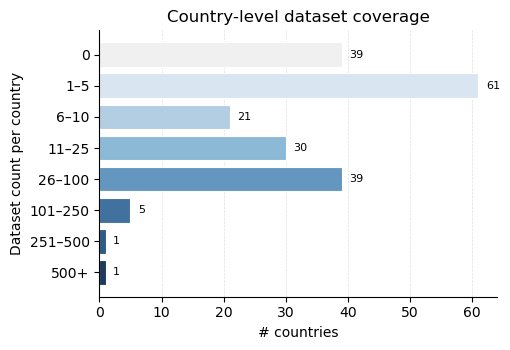

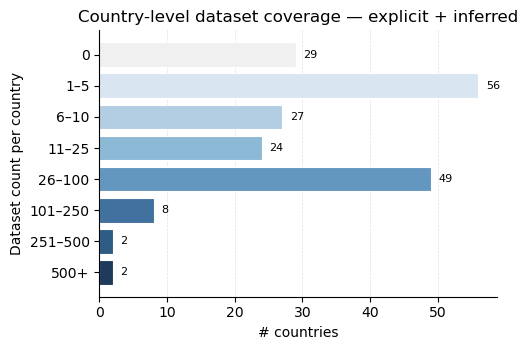

Primary top 10 countries:


,associations
United States,631
China,368
India,233
United Kingdom,216
Germany,162
France,144
Japan,130
Italy,95
Canada,89
Spain,80


In [22]:

import numpy as np
import matplotlib.pyplot as plt

def full_country_counts(expanded):
    return (
        expanded["content_country"]
        .value_counts()
        .reindex(VALID_COUNTRIES, fill_value=0)
        .sort_values(ascending=False)
    )

primary_counts = full_country_counts(explicit_country)
sensitivity_counts = full_country_counts(any_country)

def scarcity_buckets(counts):
    bins = [
        ("0", counts.eq(0)),
        ("1–5", counts.between(1, 5)),
        ("6–10", counts.between(6, 10)),
        ("11–25", counts.between(11, 25)),
        ("26–100", counts.between(26, 100)),
        ("101–250", counts.between(101, 250)),
        ("251–500", counts.between(251, 500)),
        ("500+", counts.ge(501)),
    ]
    return pd.Series({label: int(mask.sum()) for label, mask in bins})

scarcity = pd.concat(
    [
        scarcity_buckets(primary_counts).rename("explicit"),
        scarcity_buckets(sensitivity_counts).rename("explicit_plus_inferred"),
    ],
    axis=1,
)
display(scarcity)
scarcity.to_csv(OUTPUT_DIR / "country_scarcity_buckets_v2_2.csv")

SCARCITY_COLORS = [
    "#f0f0f0",
    "#d9e6f2",
    "#b3cde3",
    "#8cbad6",
    "#6497c0",
    "#41729f",
    "#2f5c85",
    "#1f3b5c",
]

def plot_scarcity_camera_ready(counts, title, stem):
    bucket = scarcity_buckets(counts)
    labels = list(bucket.index)
    y_pos = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    ax.barh(
        y_pos,
        bucket.values,
        color=SCARCITY_COLORS,
        edgecolor="white",
        linewidth=0.8,
    )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel("# countries")
    ax.set_ylabel("Dataset count per country")
    ax.set_title(title, fontsize=12)

    max_val = max(bucket.values) if len(bucket) else 1
    for y, v in zip(y_pos, bucket.values):
        ax.text(v + max_val * 0.02, y, str(v), va="center", fontsize=8)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_scarcity_camera_ready(
    primary_counts,
    "Country-level dataset coverage",
    "fig1_scarcity_explicit_camera_ready",
)
plot_scarcity_camera_ready(
    sensitivity_counts,
    "Country-level dataset coverage — explicit + inferred",
    "fig1_scarcity_explicit_plus_inferred_camera_ready",
)

print("Primary top 10 countries:")
display(primary_counts.head(10).rename("associations").to_frame())


In [33]:
# ============================================================
# Figure 1 — Country coverage map
# OLD PAPER STYLE, using POST-AUDIT counts
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go


def coverage_map_old_paper_style(
    counts,
    stem="fig1_country_coverage_map_explicit_camera_ready",
    title_text="NLP dataset record count per country",
):
    # ========================================================
    # 1. Convert current post-audit country counts to dataframe
    # ========================================================

    country_counts = (
        counts
        .rename("dataset_count")
        .rename_axis("content_country")
        .reset_index()
    )

    country_counts["content_country"] = (
        country_counts["content_country"]
        .astype(str)
        .str.strip()
    )

    country_counts = country_counts[
        country_counts["content_country"].notna()
        & (country_counts["content_country"] != "")
        & (country_counts["content_country"].str.lower() != "nan")
        & (country_counts["content_country"].str.lower() != "not stated")
    ].copy()

    # IMPORTANT:
    # The original figure was built from groupby(), so countries with
    # zero datasets were absent from the trace and therefore appeared
    # as the gray map background/land color.
    #
    # Keep that behavior here so the new figure visually matches
    # the old paper figure.
    represented_counts = country_counts[
        country_counts["dataset_count"] > 0
    ].copy()


    # ========================================================
    # 2. Bucket counts — EXACT OLD PAPER BUCKETS
    # ========================================================

    bins = [-1, 0, 5, 10, 25, 100, 250, 500, np.inf]

    bucket_labels = [
        "0",
        "1–5",
        "6–10",
        "11–25",
        "26–100",
        "101–250",
        "251–500",
        "500+",
    ]

    represented_counts["coverage_bucket"] = pd.cut(
        represented_counts["dataset_count"],
        bins=bins,
        labels=bucket_labels,
    )

    bucket_to_value = {
        bucket: i
        for i, bucket in enumerate(bucket_labels)
    }

    represented_counts["bucket_value"] = (
        represented_counts["coverage_bucket"]
        .map(bucket_to_value)
        .astype(int)
    )


    # ========================================================
    # 3. EXACT OLD PAPER COLOR PALETTE
    # ========================================================

    bucket_colors = {
        "0": "#E6E6E6",
        "1–5": "#FDB863",
        "6–10": "#FEE08B",
        "11–25": "#D9EF8B",
        "26–100": "#ABD9E9",
        "101–250": "#74ADD1",
        "251–500": "#4575B4",
        "500+": "#313695",
    }

    colorscale = [
        [
            i / (len(bucket_labels) - 1),
            bucket_colors[bucket],
        ]
        for i, bucket in enumerate(bucket_labels)
    ]


    # ========================================================
    # 4. Coverage inset — same calculation as OLD figure
    # ========================================================

    top_countries = (
        represented_counts
        .sort_values("dataset_count", ascending=False)
        .head(1)
    )

    # Match the old figure:
    # scarcity is calculated among represented countries,
    # because zero-count countries did not exist in old groupby output.
    n_leq_0 = (
        represented_counts["dataset_count"] <= 0
    ).sum()
    n_leq_10 = (
        represented_counts["dataset_count"] <= 10
    ).sum()

    n_leq_25 = (
        represented_counts["dataset_count"] <= 25
    ).sum()

    coverage_text = (
        "<b>Highest coverage</b><br>"
        + "<br>".join(
            f"{row['content_country']}: {int(row['dataset_count'])}"
            for _, row in top_countries.iterrows()
        )
        + "<br><br><b>Sparse coverage</b><br>"
        + f"39 countries have 0<br>"
        + f"{n_leq_10} countries have 1-10<br>"
        + f"{n_leq_25} countries have 1-25<br>"
    )


    # ========================================================
    # 5. Build choropleth — EXACT OLD STYLE
    # ========================================================

    fig = go.Figure()

    fig.add_trace(
        go.Choropleth(
            locations=represented_counts["content_country"],
            locationmode="country names",
            z=represented_counts["bucket_value"],
            text=represented_counts["content_country"],
            customdata=np.stack(
                [
                    represented_counts["dataset_count"],
                    represented_counts[
                        "coverage_bucket"
                    ].astype(str),
                ],
                axis=-1,
            ),
            colorscale=colorscale,
            zmin=0,
            zmax=len(bucket_labels) - 1,
            showscale=False,
            marker_line_color="white",
            marker_line_width=0.35,
            hovertemplate=(
                "<b>%{text}</b><br>"
                "Dataset count: %{customdata[0]}<br>"
                "Bucket: %{customdata[1]}"
                "<extra></extra>"
            ),
        )
    )


    # ========================================================
    # 6. Layout — EXACT OLD SIZE / MAP PLACEMENT
    # ========================================================

    fig.update_layout(
        width=700,
        height=690,
        margin=dict(
            l=5,
            r=5,
            t=85,
            b=95,
        ),
        geo=dict(
            domain=dict(
                x=[0.00, 1.00],
                y=[0.18, 0.90],
            ),
            showframe=False,
            showcoastlines=False,
            projection_type="natural earth",
            bgcolor="white",
            showland=True,
            landcolor="#E6E6E6",
        ),
        font=dict(
            family="Arial",
            size=11,
        ),
    )


    # ========================================================
    # 7. EXACT OLD CUSTOM LEGEND
    # ========================================================

    legend_y = 0.90
    box_w = 0.018
    box_h = 0.025

    legend_x = {
        "0": 0.08,
        "1–5": 0.14,
        "6–10": 0.23,
        "11–25": 0.33,
        "26–100": 0.44,
        "101–250": 0.575,
        "251–500": 0.725,
        "500+": 0.870,
    }

    fig.add_annotation(
        x=0.5,
        y=0.985,
        xref="paper",
        yref="paper",
        text=f"<b>{title_text}</b>",
        showarrow=False,
        font=dict(size=16),
    )

    for bucket in bucket_labels:
        x0 = legend_x[bucket]
        x1 = x0 + box_w

        fig.add_shape(
            type="rect",
            xref="paper",
            yref="paper",
            x0=x0,
            x1=x1,
            y0=legend_y,
            y1=legend_y + box_h,
            line=dict(
                color="rgba(0,0,0,0.3)",
                width=0.4,
            ),
            fillcolor=bucket_colors[bucket],
        )

        fig.add_annotation(
            x=x1 + 0.004,
            y=legend_y + box_h / 2,
            xref="paper",
            yref="paper",
            text=bucket,
            showarrow=False,
            xanchor="left",
            yanchor="middle",
            font=dict(size=17),
        )


    # ========================================================
    # 8. EXACT OLD COVERAGE INSET
    # ========================================================

    fig.add_annotation(
        x=0.02,
        y=0.02,
        xref="paper",
        yref="paper",
        text=coverage_text,
        showarrow=False,
        align="left",
        bgcolor="rgba(255,255,255,0.92)",
        bordercolor="rgba(80,80,80,0.35)",
        borderwidth=1,
        borderpad=6,
        font=dict(size=16),
    )


    # ========================================================
    # 9. Show + save HTML / PNG / PDF
    # ========================================================

    fig.show()

    fig.write_html(
        OUTPUT_DIR / f"{stem}.html"
    )

    fig.write_image(
        OUTPUT_DIR / f"{stem}.png",
        scale=3,
    )

    fig.write_image(
        OUTPUT_DIR / f"{stem}.pdf"
    )

    print(
        f"Saved:\n"
        f"  {OUTPUT_DIR / f'{stem}.html'}\n"
        f"  {OUTPUT_DIR / f'{stem}.png'}\n"
        f"  {OUTPUT_DIR / f'{stem}.pdf'}"
    )

    return fig


# ============================================================
# PAPER FIGURE — PRIMARY EXPLICIT-ONLY ANALYSIS
# ============================================================

fig1_explicit = coverage_map_old_paper_style(
    primary_counts,
    stem="fig1_country_coverage_map_explicit_camera_ready",
    title_text="NLP dataset record count per country",
)
# ============================================================
# APPENDIX FIGURE — EXPLICIT + INFERRED SENSITIVITY ANALYSIS
# Same styling, bins, colors, and dimensions as main Figure 1
# ============================================================

fig1_appendix_explicit_plus_inferred = coverage_map_old_paper_style(
    sensitivity_counts,
    stem="appendix_fig_country_coverage_map_explicit_plus_inferred_camera_ready",
    title_text="NLP Dataset count per country — explicit + inferred",
)

Saved:
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/fig1_country_coverage_map_explicit_camera_ready.html
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/fig1_country_coverage_map_explicit_camera_ready.png
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/fig1_country_coverage_map_explicit_camera_ready.pdf


Saved:
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_fig_country_coverage_map_explicit_plus_inferred_camera_ready.html
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_fig_country_coverage_map_explicit_plus_inferred_camera_ready.png
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_fig_country_coverage_map_explicit_plus_inferred_camera_ready.pdf


## 10. Figure 2 — country × task coverage and sparsity

In [24]:
TASKS = sorted(
    eligible.loc[eligible["normalized_task_category"].notna(), "normalized_task_category"]
    .astype(str).unique()
)
print("Task categories in eligible Core:", len(TASKS))

def country_task_matrix(expanded):
    ct = (
        expanded.groupby(["content_country", "normalized_task_category"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=VALID_COUNTRIES, columns=TASKS, fill_value=0)
    )
    return ct

pivot_explicit = country_task_matrix(explicit_country)
pivot_sensitivity = country_task_matrix(any_country)

def sparsity_stats(pivot):
    total = pivot.shape[0] * pivot.shape[1]
    empty = int((pivot == 0).to_numpy().sum())
    return pd.Series({
        "countries": pivot.shape[0],
        "tasks": pivot.shape[1],
        "cells": total,
        "empty_cells": empty,
        "empty_share": empty / total,
    })

country_task_sparsity = pd.concat(
    [
        sparsity_stats(pivot_explicit).rename("explicit"),
        sparsity_stats(pivot_sensitivity).rename("explicit_plus_inferred"),
    ],
    axis=1,
).T
display(country_task_sparsity.style.format({"empty_share": "{:.1%}"}))
country_task_sparsity.to_csv(OUTPUT_DIR / "country_task_sparsity_v2_2.csv")

Task categories in eligible Core: 30


,countries,tasks,cells,empty_cells,empty_share
explicit,197.000000,30.000000,5910.000000,4679.000000,79.2%
explicit_plus_inferred,197.000000,30.000000,5910.000000,4430.000000,75.0%


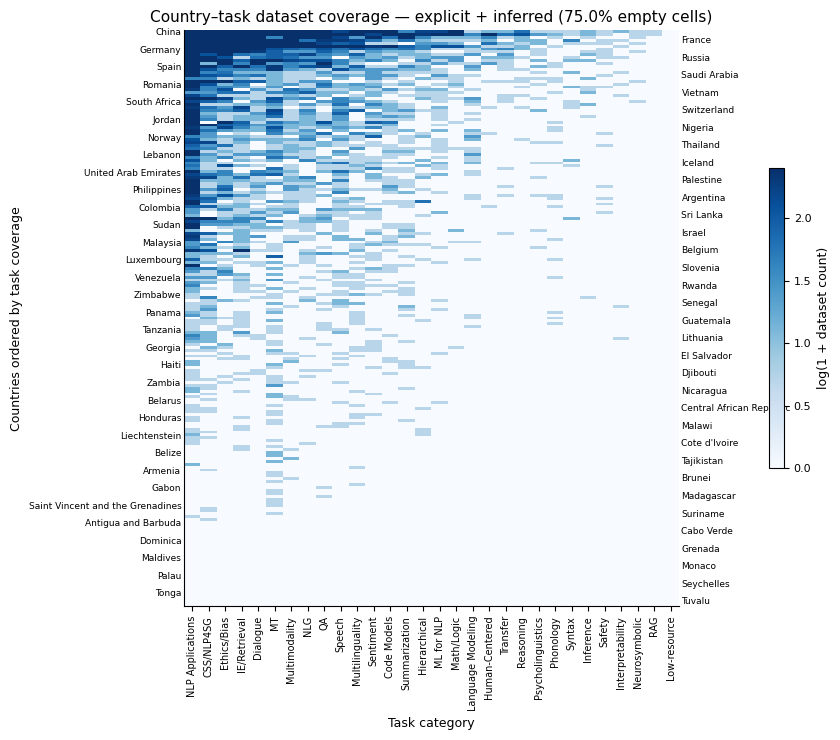

Saved:
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/fig2_country_task_explicit_plus_inferred_camera_ready.pdf
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/fig2_country_task_explicit_plus_inferred_camera_ready.png


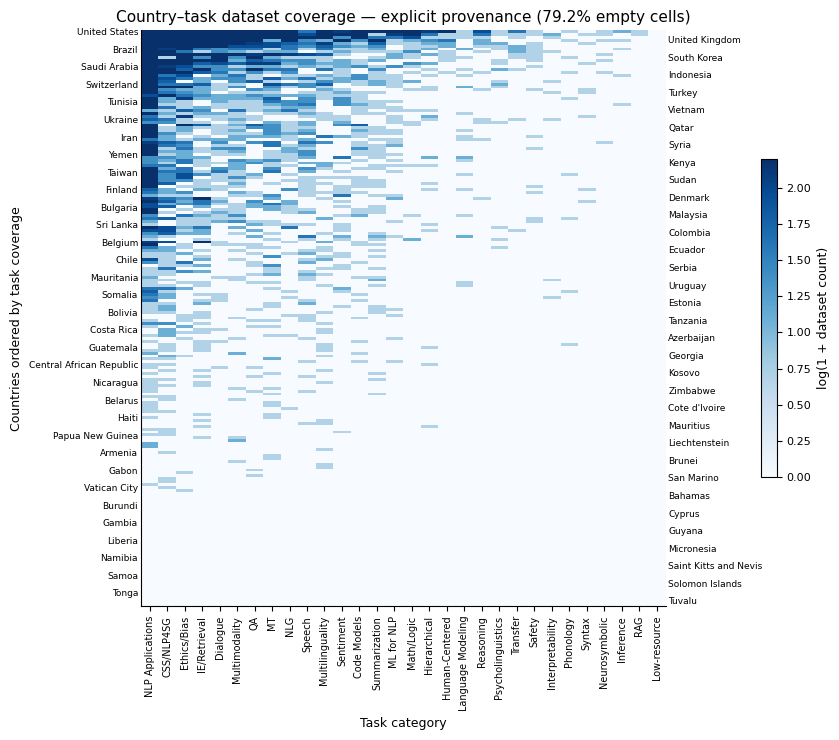

Saved:
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_fig2_country_task_explicit_camera_ready.pdf
  /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_fig2_country_task_explicit_camera_ready.png


In [25]:
TASK_SHORT = {
    'Human-AI Interaction/Cooperation, Human Centered NLP': 'Human-Centered',
    'Phonology, morphology, and word segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval Augmented Language Models': 'RAG',
    'Neurosymbolic approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for social good': 'CSS/NLP4SG',
    'Dialogue and Interactive Systems': 'Dialogue',
    'Discourse, Pragmatics and Reasoning': 'Reasoning',
    'Efficient/Low-Resource Methods for NLP, LLM Efficiency': 'Low-resource',
    'Ethics, Bias, and Fairness': 'Ethics/Bias',
    'Generalizability and Transfer': 'Transfer',
    'Information Extraction, Retrieval, and Text Mining': 'IE/Retrieval',
    'Interpretability, Model Analysis, Transparency, and Explainability': 'Interpretability',
    'Machine Learning for NLP': 'ML for NLP',
    'Machine Translation': 'MT',
    'Natural Language Generation': 'NLG',
    'Question Answering': 'QA',
    'Multimodality and Language Grounding to Vision, Robotics and Beyond': 'Multimodality',
    'Sentiment Analysis, Stylistic Analysis, and Argument Mining': 'Sentiment',
    'Speech recognition, text-to-speech, and spoken language understanding': 'Speech',
    'Hierarchical Structure Prediction, Syntax, and Parsing': 'Hierarchical',
    'Multilinguality and Language Diversity': 'Multilinguality',
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax',
}

def plot_full_country_task_camera_ready(pivot, title_prefix, stem):

    # ========================================================
    # 1. Country ordering
    # ========================================================

    # Match paper ordering:
    # first by task breadth, then by total dataset coverage.
    task_coverage = (pivot > 0).sum(axis=1)
    dataset_counts = pivot.sum(axis=1)

    country_order = (
        pd.DataFrame({
            "task_coverage": task_coverage,
            "dataset_count": dataset_counts,
        })
        .sort_values(
            ["task_coverage", "dataset_count"],
            ascending=False,
        )
        .index
    )

    ordered = pivot.loc[country_order]


    # ========================================================
    # 2. Task ordering
    # ========================================================

    task_order = (
        ordered.sum(axis=0)
        .sort_values(ascending=False)
        .index
    )

    ordered = (
        ordered[task_order]
        .rename(columns=TASK_SHORT)
    )


    # ========================================================
    # 3. Sparsity + transformed heatmap values
    # ========================================================

    num_cells = ordered.shape[0] * ordered.shape[1]

    zero_pct = (
        100
        * (ordered == 0).sum().sum()
        / num_cells
    )

    heatmap_values = np.log1p(
        ordered.to_numpy(dtype=float)
    )


    # ========================================================
    # 4. Figure
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(8.5, 7.5)
    )

    im = ax.imshow(
        heatmap_values,
        aspect="auto",
        interpolation="nearest",
        cmap="Blues",
        vmax=np.percentile(
            heatmap_values,
            98
        ),
        origin="upper",
    )

    # Explicitly rasterize only the heatmap.
    # Text remains vector in the PDF.
    im.set_rasterized(True)


    # ========================================================
    # 5. Colorbar
    # ========================================================

    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.025,
        pad=0.15,
    )

    cbar.set_label(
        "log(1 + dataset count)",
        fontsize=9,
    )

    cbar.ax.tick_params(
        labelsize=8
    )


    # ========================================================
    # 6. Task labels
    # ========================================================

    ax.set_xticks(
        np.arange(len(ordered.columns))
    )

    ax.set_xticklabels(
        ordered.columns,
        rotation=90,
        ha="center",
        fontsize=7,
    )


    # ========================================================
    # 7. Country labels
    #
    # IMPORTANT:
    # Do NOT use ax.twinx().
    # It is causing the corrupted PDF rendering.
    # ========================================================

    n_countries = len(ordered.index)

    target_total_labels = 60

    step = max(
        1,
        n_countries // target_total_labels
    )

    yticks_all = np.arange(
        0,
        n_countries,
        step
    )

    yticks_left = yticks_all[::2]
    yticks_right = yticks_all[1::2]


    # ------------------------
    # LEFT labels
    # ------------------------

    ax.set_yticks(yticks_left)

    ax.set_yticklabels(
        ordered.index[yticks_left],
        fontsize=6.5,
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=2,
    )


    # ------------------------
    # RIGHT labels
    #
    # x uses axes coordinates:
    #   1.0 = right edge of heatmap
    #
    # y remains in heatmap/data coordinates.
    # ------------------------

    right_transform = ax.get_yaxis_transform()

    for y in yticks_right:
        ax.text(
            1.005,
            y,
            ordered.index[y],
            transform=right_transform,
            ha="left",
            va="center",
            fontsize=6.5,
            clip_on=False,
        )


    # ========================================================
    # 8. Labels + title
    # ========================================================

    ax.set_xlabel(
        "Task category",
        fontsize=9,
    )

    ax.set_ylabel(
        "Countries ordered by task coverage",
        fontsize=9,
    )

    ax.set_title(
        f"{title_prefix} "
        f"({zero_pct:.1f}% empty cells)",
        fontsize=11,
    )


    # ========================================================
    # 9. Styling
    # ========================================================

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Give the manually drawn right labels room.
    fig.subplots_adjust(
        right=0.82
    )

    plt.tight_layout()


    # ========================================================
    # 10. Export
    # ========================================================

    # PDF:
    # heatmap rasterized at high DPI;
    # labels/title remain vector.
    fig.savefig(
        OUTPUT_DIR / f"{stem}.pdf",
        format="pdf",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    # PNG
    fig.savefig(
        OUTPUT_DIR / f"{stem}.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()

    print(
        f"Saved:\n"
        f"  {OUTPUT_DIR / f'{stem}.pdf'}\n"
        f"  {OUTPUT_DIR / f'{stem}.png'}"
    )

    return fig, ordered

# MAIN PAPER — explicit + inferred
fig2_main, fig2_main_data = plot_full_country_task_camera_ready(
    pivot_sensitivity,
    "Country–task dataset coverage — explicit + inferred",
    "fig2_country_task_explicit_plus_inferred_camera_ready",
)

# APPENDIX / sensitivity — explicit only
fig2_explicit, fig2_explicit_data = plot_full_country_task_camera_ready(
    pivot_explicit,
    "Country–task dataset coverage — explicit provenance",
    "appendix_fig2_country_task_explicit_camera_ready",
)

Country-task matrix shape: (197, 30)
Zero country-task cells: 79.2%
Saved PNG: /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_country_task_explicit_camera_ready.png
Saved raster PDF: /home/jnwatu/Worldbench/Post_audit_analysis/post_audit_outputs_camera_ready_style/appendix_country_task_explicit_camera_ready.pdf


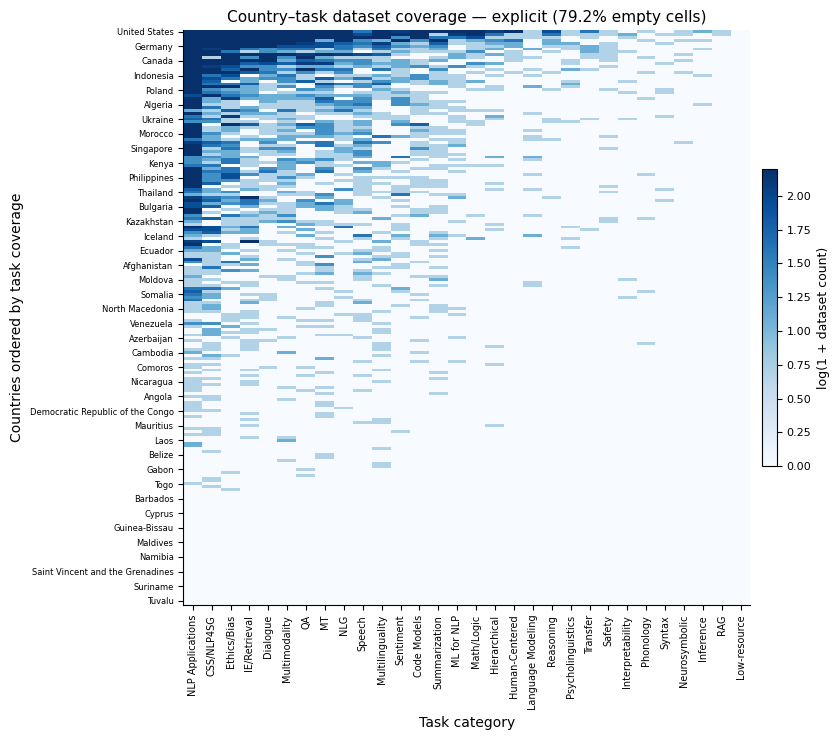

In [26]:
import matplotlib.pyplot as plt
TASK_SHORT = {
    'Human-AI Interaction/Cooperation, Human Centered NLP': 'Human-Centered',
    'Phonology, morphology, and word segmentation': 'Phonology',
    'Linguistic Theories, Cognitive Modeling, and Psycholinguistics': 'Psycholinguistics',
    'Safety and Alignment in LLMs': 'Safety',
    'Semantics: Lexical and Sentence Level, Textual Inference': 'Inference',
    'Mathematical, Symbolic, and Logical Reasoning in NLP': 'Math/Logic',
    'Retrieval Augmented Language Models': 'RAG',
    'Neurosymbolic approaches to NLP': 'Neurosymbolic',
    'Computational Social Science, Cultural Analytics, NLP for social good': 'CSS/NLP4SG',
    'Dialogue and Interactive Systems': 'Dialogue',
    'Discourse, Pragmatics and Reasoning': 'Reasoning',
    'Efficient/Low-Resource Methods for NLP, LLM Efficiency': 'Low-resource',
    'Ethics, Bias, and Fairness': 'Ethics/Bias',
    'Generalizability and Transfer': 'Transfer',
    'Information Extraction, Retrieval, and Text Mining': 'IE/Retrieval',
    'Interpretability, Model Analysis, Transparency, and Explainability': 'Interpretability',
    'Machine Learning for NLP': 'ML for NLP',
    'Machine Translation': 'MT',
    'Natural Language Generation': 'NLG',
    'Question Answering': 'QA',
    'Multimodality and Language Grounding to Vision, Robotics and Beyond': 'Multimodality',
    'Sentiment Analysis, Stylistic Analysis, and Argument Mining': 'Sentiment',
    'Speech recognition, text-to-speech, and spoken language understanding': 'Speech',
    'Hierarchical Structure Prediction, Syntax, and Parsing': 'Hierarchical',
    'Multilinguality and Language Diversity': 'Multilinguality',
    'Syntax: Tagging, Chunking, and Parsing': 'Syntax',
}

pivot = pivot_explicit
#pivot = pivot_sensitivity
# --- Order countries by task coverage, then dataset count ---
task_coverage = (pivot > 0).sum(axis=1)
dataset_counts = pivot.sum(axis=1)

country_order = (
    pd.DataFrame({
        "task_coverage": task_coverage,
        "dataset_count": dataset_counts
    })
    .sort_values(["task_coverage", "dataset_count"], ascending=False)
    .index
)

pivot_ordered = pivot.loc[country_order]

# --- Order tasks by total dataset count ---
task_order = pivot_ordered.sum(axis=0).sort_values(ascending=False).index
pivot_ordered = pivot_ordered[task_order]

# --- Shorten task names AFTER ordering ---
pivot_ordered = pivot_ordered.rename(columns=TASK_SHORT)

# --- Sparsity statistic ---
num_cells = pivot_ordered.shape[0] * pivot_ordered.shape[1]
num_zero_cells = (pivot_ordered == 0).sum().sum()
zero_pct = 100 * num_zero_cells / num_cells

print(f"Country-task matrix shape: {pivot_ordered.shape}")
print(f"Zero country-task cells: {zero_pct:.1f}%")

# --- Log transform for visualization ---
heatmap_values = np.log1p(pivot_ordered.values)

# --- Plot ---
fig, ax = plt.subplots(figsize=(8.5, 7.5))

im = ax.imshow(
    heatmap_values,
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
    vmax=np.percentile(heatmap_values, 98)
)

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("log(1 + dataset count)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# X-axis task labels
ax.set_xticks(np.arange(len(pivot_ordered.columns)))
ax.set_xticklabels(
    pivot_ordered.columns,
    rotation=90,
    ha="center",
    fontsize=7
)

# Label every nth country to avoid clutter
n_countries = len(pivot_ordered.index)
step = max(1, n_countries // 35)

yticks = np.arange(0, n_countries, step)
ax.set_yticks(yticks)
ax.set_yticklabels(
    pivot_ordered.index[yticks],
    fontsize=6
)

ax.set_xlabel("Task category")
ax.set_ylabel("Countries ordered by task coverage")
ax.set_title(
    f"Country–task dataset coverage — explicit ({zero_pct:.1f}% empty cells)",
    fontsize=11
)

# Clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# ============================================================
# SAVE — PDF-SAFE VERSION
#
# Render once with the PNG/Agg backend, then wrap that exact
# raster image in a PDF. This bypasses Matplotlib's PDF backend.
# ============================================================

from PIL import Image

# png_path = (
#     OUTPUT_DIR
#     / "fig2_country_task_explicit_plus_inferred_camera_ready.png"
# )

# pdf_path = (
#     OUTPUT_DIR
#     / "fig2_country_task_explicit_plus_inferred_camera_ready.pdf"
# )


png_path = (
    OUTPUT_DIR
    / "appendix_country_task_explicit_camera_ready.png"
)

pdf_path = (
    OUTPUT_DIR
    / "appendix_country_task_explicit_camera_ready.pdf"
)

# ------------------------------------------------------------
# 1. Save the CORRECT rendering at high resolution
# ------------------------------------------------------------

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)


# ------------------------------------------------------------
# 2. Convert that exact PNG to PDF
#    This does NOT invoke Matplotlib's PDF backend.
# ------------------------------------------------------------

with Image.open(png_path) as img:
    img = img.convert("RGB")

    img.save(
        pdf_path,
        "PDF",
        resolution=600.0
    )


print(f"Saved PNG: {png_path}")
print(f"Saved raster PDF: {pdf_path}")

plt.show()

## 11. Section 5.4 / Table 4 — country task portfolios

Explicit-only countries with >=10 associations: 77
Median task breadth: 11.0
Median top-3 share: 55.6%


,country,dataset_count,task_breadth,top3_share
11,China,368,27,0.483696
74,United States,631,27,0.500792
19,France,144,22,0.444444
25,India,233,22,0.459227
73,United Kingdom,216,22,0.490741
7,Brazil,71,21,0.450704
20,Germany,162,21,0.574074
55,Russia,51,20,0.490196
32,Japan,130,19,0.415385
60,South Korea,74,19,0.608108


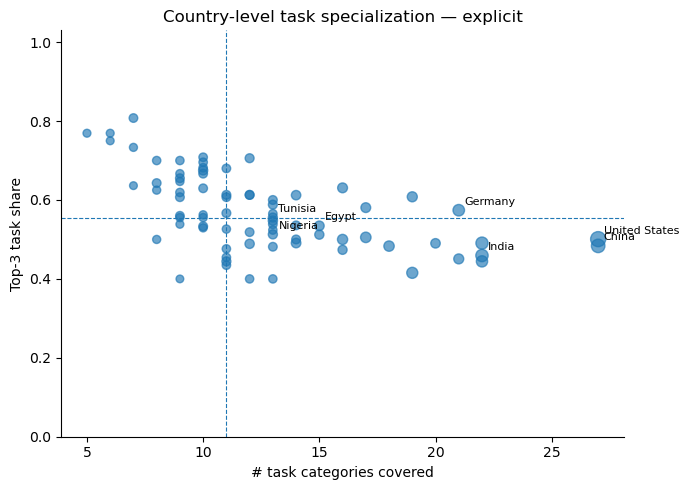

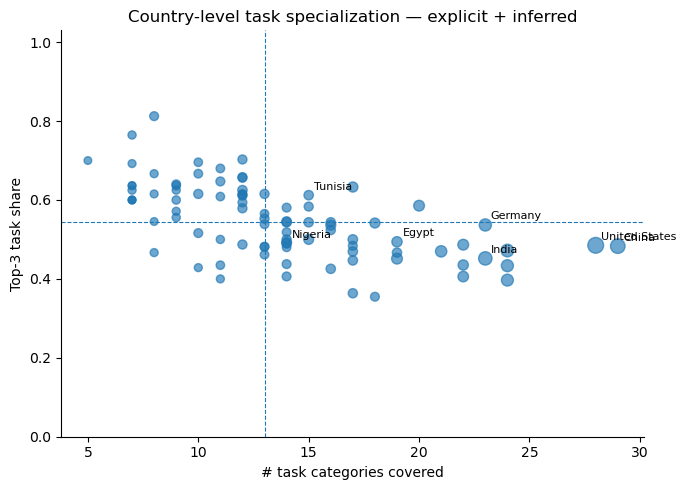

In [27]:
def task_portfolios(pivot, min_associations=10):
    totals = pivot.sum(axis=1)
    p = pivot.loc[totals >= min_associations].copy()
    task_breadth = (p > 0).sum(axis=1)
    top3_share = p.apply(
        lambda row: row.sort_values(ascending=False).head(3).sum() / row.sum()
        if row.sum() > 0 else np.nan,
        axis=1,
    )
    out = pd.DataFrame({
        "country": p.index,
        "dataset_count": p.sum(axis=1).astype(int),
        "task_breadth": task_breadth.astype(int),
        "top3_share": top3_share,
    }).reset_index(drop=True)
    return out

portfolio_explicit = task_portfolios(pivot_explicit)
portfolio_sensitivity = task_portfolios(pivot_sensitivity)

print("Explicit-only countries with >=10 associations:", len(portfolio_explicit))
print("Median task breadth:", portfolio_explicit["task_breadth"].median())
print("Median top-3 share:", f"{portfolio_explicit['top3_share'].median():.1%}")
display(portfolio_explicit.sort_values(["task_breadth", "top3_share"], ascending=[False, True]).head(15))

portfolio_explicit.to_csv(OUTPUT_DIR / "task_portfolios_explicit.csv", index=False)
portfolio_sensitivity.to_csv(OUTPUT_DIR / "task_portfolios_explicit_plus_inferred.csv", index=False)

def plot_task_specialization(df, title, stem):
    fig, ax = plt.subplots(figsize=(7, 5))
    sizes = 18 + 4 * np.sqrt(df["dataset_count"])
    ax.scatter(df["task_breadth"], df["top3_share"], s=sizes, alpha=0.65)
    ax.axvline(df["task_breadth"].median(), linestyle="--", linewidth=0.8)
    ax.axhline(df["top3_share"].median(), linestyle="--", linewidth=0.8)
    ax.set_xlabel("# task categories covered")
    ax.set_ylabel("Top-3 task share")
    ax.set_ylim(0, 1.03)
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for country in ["United States", "China", "India", "Germany", "Nigeria", "Egypt", "Tunisia"]:
        row = df[df["country"] == country]
        if len(row):
            r = row.iloc[0]
            ax.annotate(country, (r["task_breadth"], r["top3_share"]), xytext=(4, 4), textcoords="offset points", fontsize=8)

    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()

plot_task_specialization(portfolio_explicit, "Country-level task specialization — explicit", "task_specialization_explicit")
plot_task_specialization(portfolio_sensitivity, "Country-level task specialization — explicit + inferred", "task_specialization_explicit_plus_inferred")

### Temporal specialization note

The submitted paper also contained an exploratory pre/post temporal specialization analysis. The frozen v2.2 CSVs uploaded here do **not** contain a publication-year column, so that analysis is not silently reconstructed from ACL paper IDs. It should be rerun only after a verified paper-year field is joined back to the v2.2 records.

## 12. Figure 3 — producer vs. represented geography

In [28]:
PRODUCER_ALIAS_MAP = {
    "Jersey": "United Kingdom",
    "Montserrat": "United Kingdom",
    "Réunion": "France",
    "Republic of Guyana": "Guyana",
    "State of Kuwait": "Kuwait",
    "Sultanate of Oman": "Oman",
    "Viet Nam": "Vietnam",
}

def normalize_producer_list(x):
    out = []
    for c in parse_list_field(x):
        c = PRODUCER_ALIAS_MAP.get(c, c)
        if c in VALID_COUNTRY_SET and c not in out:
            out.append(c)
    return out

def build_producer_content_analysis(expanded):
    d = expanded.copy()
    d["producer_list"] = d["producer_country_list"].apply(normalize_producer_list)
    d = d[d["content_country"].notna() & d["producer_list"].map(len).gt(0)].copy()

    d["content_is_self"] = d.apply(
        lambda r: r["content_country"] in r["producer_list"], axis=1
    )
    content_summary = (
        d.groupby("content_country")
        .agg(content_self=("content_is_self", "mean"),
             content_count=("content_country", "size"))
        .reset_index()
        .rename(columns={"content_country": "country"})
    )

    prod = d.explode("producer_list").rename(columns={"producer_list": "producer_country"}).copy()
    prod["producer_is_self"] = prod["producer_country"] == prod["content_country"]

    producer_summary = (
        prod.groupby("producer_country")
        .agg(producer_self=("producer_is_self", "mean"),
             producer_count=("producer_country", "size"))
        .reset_index()
        .rename(columns={"producer_country": "country"})
    )

    compare = content_summary.merge(producer_summary, on="country", how="inner")
    return d, prod, compare

explicit_pc_rows, explicit_pc_cross, country_compare_explicit = build_producer_content_analysis(explicit_country)
sensitivity_pc_rows, sensitivity_pc_cross, country_compare_sensitivity = build_producer_content_analysis(any_country)

def cross_summary(name, rows, cross):
    counts = cross["producer_country"].value_counts()
    return {
        "specification": name,
        "records_with_content_and_producer": rows["audit_record_id"].nunique(),
        "content_country_associations_with_producer": len(rows),
        "content_x_producer_associations": len(cross),
        "US_share": counts.get("United States", 0) / len(cross),
        "top10_producer_share": counts.head(10).sum() / len(cross),
    }

producer_cross_compare = pd.DataFrame([
    cross_summary("Primary: explicit only", explicit_pc_rows, explicit_pc_cross),
    cross_summary("Sensitivity: explicit + inferred", sensitivity_pc_rows, sensitivity_pc_cross),
]).set_index("specification")
display(producer_cross_compare.style.format({"US_share": "{:.1%}", "top10_producer_share": "{:.1%}"}))
producer_cross_compare.to_csv(OUTPUT_DIR / "producer_cross_denominators_v2_2.csv")

,records_with_content_and_producer,content_country_associations_with_producer,content_x_producer_associations,US_share,top10_producer_share
specification,,,,,
Primary: explicit only,2396,4305,6532,21.3%,61.1%
Sensitivity: explicit + inferred,3438,5836,9013,20.7%,61.1%


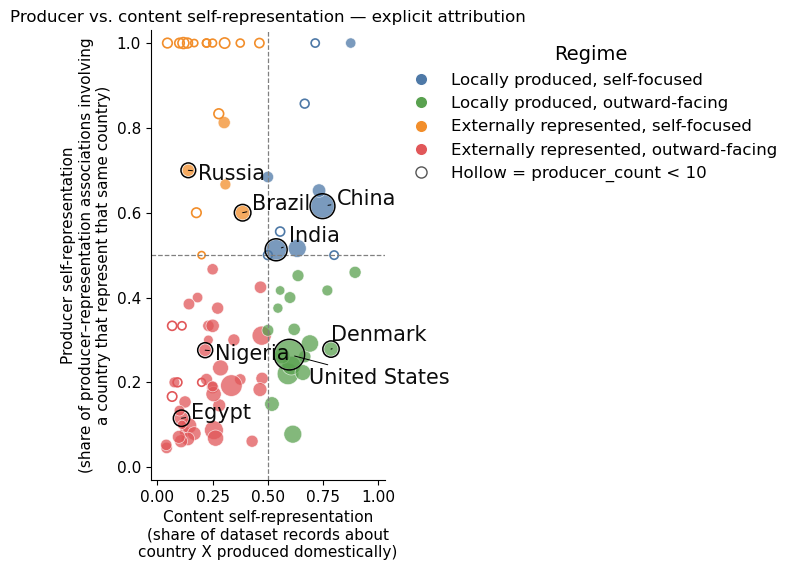

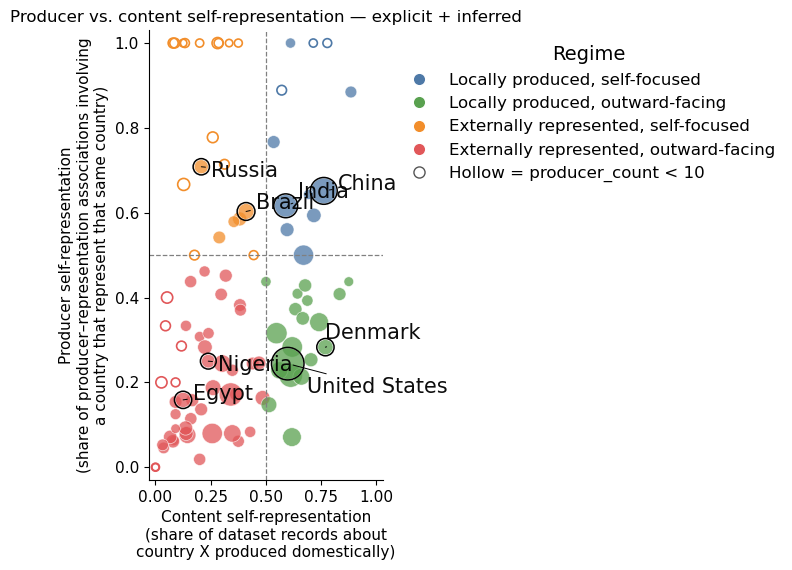

In [30]:

def classify_regime(row):
    if row["content_self"] >= 0.5 and row["producer_self"] >= 0.5:
        return "Locally produced, self-focused"
    if row["content_self"] >= 0.5 and row["producer_self"] < 0.5:
        return "Locally produced, outward-facing"
    if row["content_self"] < 0.5 and row["producer_self"] >= 0.5:
        return "Externally represented, self-focused"
    return "Externally represented, outward-facing"

def prepare_regime_table(compare, min_content=5):
    out = compare.copy()
    out["regime"] = out.apply(classify_regime, axis=1)
    out["hollow_low_n"] = out["producer_count"] < 10
    out["total_volume"] = out["content_count"] + out["producer_count"]
    return out[
        (out["content_count"] >= min_content)
        & (out["producer_count"] >= 1)
    ].copy()

regime_explicit = prepare_regime_table(country_compare_explicit)
regime_sensitivity = prepare_regime_table(country_compare_sensitivity)

regime_explicit.to_csv(
    OUTPUT_DIR / "figure3_country_self_representation_explicit.csv",
    index=False,
)
regime_sensitivity.to_csv(
    OUTPUT_DIR / "figure3_country_self_representation_explicit_plus_inferred.csv",
    index=False,
)


from matplotlib.lines import Line2D

REGIME_COLORS = {
    "Locally produced, self-focused":         "#4E79A7",
    "Locally produced, outward-facing":       "#59A14F",
    "Externally represented, self-focused":   "#F28E2B",
    "Externally represented, outward-facing": "#E15759",
}

# These are the camera-ready spotlight countries used to illustrate
# the four regimes in the paper/rebuttal-era figure.
SPOTLIGHT_COUNTRIES = [
    "China",
    "India",
    "United States",
    "Denmark",
    "Nigeria",
    "Egypt",
    "Russia",
    "Brazil",
]

SPOTLIGHT_OFFSETS = {
    "China": (10, 5),
    "India": (9, 10),
    "United States": (14, -17),
    "Denmark": (0, 10),
    "Nigeria": (7, -3),
    "Egypt": (7, 4),
    "Russia": (7, -3),
    "Brazil": (7, 6),
}

def plot_regime_camera_ready(df, title, stem):
    plot_df = df.copy()

    fig, ax = plt.subplots(figsize=(7.6, 5.8))

    for regime, sub in plot_df.groupby("regime"):
        color = REGIME_COLORS[regime]
        solid = sub[~sub["hollow_low_n"]]
        hollow = sub[sub["hollow_low_n"]]

        ax.scatter(
            solid["content_self"],
            solid["producer_self"],
            s=10 * np.sqrt(solid["total_volume"]),
            color=color,
            alpha=0.75,
            edgecolor="white",
            linewidth=0.5,
            label=regime,
        )
        ax.scatter(
            hollow["content_self"],
            hollow["producer_self"],
            s=10 * np.sqrt(hollow["total_volume"]),
            facecolors="none",
            edgecolors=color,
            linewidth=1.2,
            label="_nolegend_",
        )

    ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.9)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.9)

    # Quadrant labels from the camera-ready cell.
#     ax.text(0.74, 0.97, "Locally produced\nself-focused",
#             fontsize=7.5, ha="center", va="top", color="#333333")
#     ax.text(0.24, 0.97, "Externally represented\nself-focused",
#             fontsize=7.5, ha="center", va="top", color="#333333")
#     ax.text(0.74, 0.01, "Locally produced\noutward-facing",
#             fontsize=7.5, ha="center", va="bottom", color="#333333")
#     ax.text(0.24, 0.01, "Externally represented\noutward-facing",
#             fontsize=7.5, ha="center", va="bottom", color="#333333")

    #label_df = plot_df[plot_df["country"].isin(SPOTLIGHT_COUNTRIES)]
        # Highlight and label spotlight countries
    label_df = plot_df[plot_df["country"].isin(SPOTLIGHT_COUNTRIES)]

    for _, row in label_df.iterrows():
        country = row["country"]
        x = row["content_self"]
        y = row["producer_self"]
        dx, dy = SPOTLIGHT_OFFSETS.get(country, (5, 5))

        # Draw a black ring around the actual country marker
        ax.scatter(
            [x], [y],
            s=10 * np.sqrt(row["total_volume"]) + 35,
            facecolors="none",
            edgecolors="black",
            linewidth=1.1,
            zorder=5,
        )

        # Label with a leader line pointing to the marker
        ax.annotate(
            country,
            xy=(x, y),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=15,
            alpha=0.95,
            ha="left" if dx >= 0 else "right",
            va="center",
            arrowprops=dict(
                arrowstyle="-",
                linewidth=0.7,
                shrinkA=2,
                shrinkB=4,
            ),
            zorder=6,
        )
#     for _, row in label_df.iterrows():
#         dx, dy = SPOTLIGHT_OFFSETS.get(row["country"], (5, 5))
#         ax.annotate(
#             row["country"],
#             (row["content_self"], row["producer_self"]),
#             xytext=(dx, dy),
#             textcoords="offset points",
#             fontsize=9,
#             alpha=0.95,
#         )

    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel(
        "Content self-representation\n"
        "(share of dataset records about\n"
         "country X produced domestically)",
        fontsize=11,
    )
    ax.set_ylabel(
        "Producer self-representation\n"
        "(share of producer–representation associations involving\n"
        "a country that represent that same country)",
        fontsize=11,
    ) 
    ax.set_title(title, fontsize=12)

    legend_elements = [
        Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor=REGIME_COLORS[r],
            markersize=9, label=r,
        )
        for r in [
            "Locally produced, self-focused",
            "Locally produced, outward-facing",
            "Externally represented, self-focused",
            "Externally represented, outward-facing",
        ]
    ] + [
        Line2D(
            [0], [0], marker="o", color="w",
            markerfacecolor="none",
            markeredgecolor="#555555",
            markersize=8,
            label="Hollow = producer_count < 10",
        )
    ]
    ax.legend(
        handles=legend_elements,
        title="Regime",
        fontsize=12,
        title_fontsize=14,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=11)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_regime_camera_ready(
    regime_explicit,
    "Producer vs. content self-representation — explicit attribution",
    "fig3_producer_content_explicit_camera_ready",
)
plot_regime_camera_ready(
    regime_sensitivity,
    "Producer vs. content self-representation — explicit + inferred",
    "fig3_producer_content_explicit_plus_inferred_camera_ready",
)


In [31]:
regime_sensitivity[regime_sensitivity["country"].isin(SPOTLIGHT_COUNTRIES)]

,country,content_self,content_count,producer_self,producer_count,regime,hollow_low_n,total_volume
9,Brazil,0.410000,100,0.602941,68,"Externally represented, self-focused",False,168
13,China,0.761905,525,0.651466,614,"Locally produced, self-focused",False,1139
18,Denmark,0.769231,39,0.283019,106,"Locally produced, outward-facing",False,145
20,Egypt,0.125000,80,0.158730,63,"Externally represented, outward-facing",False,143
33,India,0.589595,346,0.616314,331,"Locally produced, self-focused",False,677
64,Nigeria,0.239130,46,0.250000,44,"Externally represented, outward-facing",False,90
77,Russia,0.207317,82,0.708333,24,"Externally represented, self-focused",False,106
102,United States,0.598684,760,0.244099,1864,"Locally produced, outward-facing",False,2624


In [32]:
#regime_sensitivity[regime_sensitivity["regime"] == 'Locally produced, outward-facing']

In [33]:
#regime_sensitivity[regime_sensitivity["regime"] == 'Externally represented, self-focused']

## 13. Figure 4 — represented coverage and research infrastructure

In [34]:
from scipy.stats import pearsonr, spearmanr

country_income_clean = country_income.copy()
country_income_clean["Country"] = country_income_clean["Country"].astype(str).str.strip()
country_income_clean["No of Universities"] = pd.to_numeric(
    country_income_clean["No of Universities"], errors="coerce"
)

def infrastructure_table(country_counts):
    counts = country_counts.rename("content_count").rename_axis("Country").reset_index()
    df = country_income_clean.merge(counts, on="Country", how="left")
    df["content_count"] = df["content_count"].fillna(0).astype(int)
    return df

infra_explicit = infrastructure_table(primary_counts)
infra_sensitivity = infrastructure_table(sensitivity_counts)

def infrastructure_stats(df, label):
    reg = df[(df["No of Universities"] > 0) & (df["content_count"] > 0)].copy()
    pear = pearsonr(np.log10(reg["No of Universities"]), np.log10(reg["content_count"]))
    spear = spearmanr(reg["No of Universities"], reg["content_count"])
    return {
        "specification": label,
        "countries_in_correlation": len(reg),
        "pearson_loglog_r": pear.statistic,
        "pearson_p": pear.pvalue,
        "spearman_rho": spear.statistic,
        "spearman_p": spear.pvalue,
    }

infra_stats_df = pd.DataFrame([
    infrastructure_stats(infra_explicit, "Primary: explicit only"),
    infrastructure_stats(infra_sensitivity, "Sensitivity: explicit + inferred"),
]).set_index("specification")
display(infra_stats_df)
infra_stats_df.to_csv(OUTPUT_DIR / "infrastructure_correlations_v2_2.csv")

print("Median content associations by income group:")
display(pd.concat([
    infra_explicit.groupby("Income")["content_count"].median().rename("explicit"),
    infra_sensitivity.groupby("Income")["content_count"].median().rename("explicit_plus_inferred"),
], axis=1))

,countries_in_correlation,pearson_loglog_r,pearson_p,spearman_rho,spearman_p
specification,,,,,
Primary: explicit only,157,0.653038,1.889060e-20,0.612061,1.644390e-17
Sensitivity: explicit + inferred,167,0.696674,1.400274e-25,0.671195,3.234047e-23


Median content associations by income group:


,explicit,explicit_plus_inferred
Income,,
H,19.5,25.0
L,2.5,3.5
LM,3.0,4.5
UM,4.0,6.0


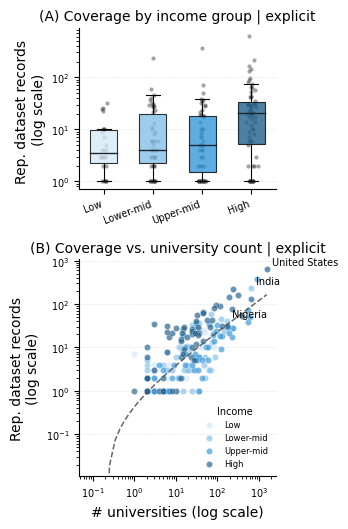

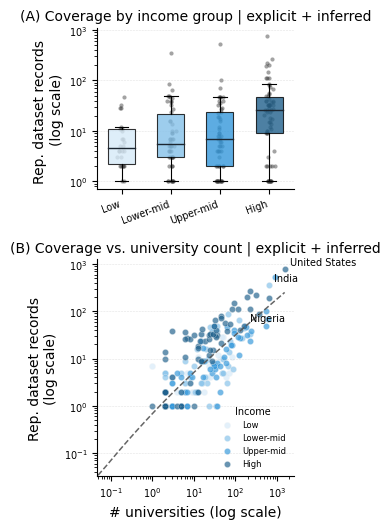

In [42]:

INCOME_ORDER = ["L", "LM", "UM", "H"]
INCOME_LABELS = {
    "L": "Low",
    "LM": "Lower-mid",
    "UM": "Upper-mid",
    "H": "High",
}
INCOME_COLORS = {
    "Low": "#D6EAF8",
    "Lower-mid": "#85C1E9",
    "Upper-mid": "#3498DB",
    "High": "#21618C",
}

def plot_infrastructure_camera_ready(df, title_suffix, stem):
    plot_df = df[df["Income"].isin(INCOME_ORDER)].copy()
    plot_df["income_label"] = plot_df["Income"].map(INCOME_LABELS)
    plot_df["income_label"] = pd.Categorical(
        plot_df["income_label"],
        categories=[INCOME_LABELS[x] for x in INCOME_ORDER],
        ordered=True,
    )

    fig, axes = plt.subplots(
        2, 1,
        figsize=(3.55, 5.4),
        gridspec_kw={"height_ratios": [1, 1.35]},
    )
    ax1, ax2 = axes

    # Panel A
    box_data = [
        plot_df.loc[plot_df["Income"] == inc, "content_count"] + 1
        for inc in INCOME_ORDER
    ]
    box = ax1.boxplot(
        box_data,
        patch_artist=True,
        widths=0.55,
        showfliers=False,
        medianprops=dict(color="#1B2631", linewidth=1),
        boxprops=dict(linewidth=0.8),
        whiskerprops=dict(linewidth=0.8),
        capprops=dict(linewidth=0.8),
    )
    for patch, inc in zip(box["boxes"], INCOME_ORDER):
        patch.set_facecolor(INCOME_COLORS[INCOME_LABELS[inc]])
        patch.set_alpha(0.8)

    rng = np.random.default_rng(42)
    for i, inc in enumerate(INCOME_ORDER, start=1):
        vals = plot_df.loc[plot_df["Income"] == inc, "content_count"] + 1
        jitter = rng.normal(loc=i, scale=0.045, size=len(vals))
        ax1.scatter(
            jitter, vals,
            s=9, alpha=0.45, color="#333333", linewidth=0,
        )

    ax1.set_yscale("log")
    ax1.set_xticks(range(1, len(INCOME_ORDER) + 1))
    ax1.set_xticklabels(
        [INCOME_LABELS[x] for x in INCOME_ORDER],
        rotation=20,
        ha="right",
    )
    ax1.set_ylabel("Rep. dataset records \n(log scale)")
    ax1.set_title(f"(A) Coverage by income group{title_suffix}", fontsize=10)

    # Panel B
    for label in [INCOME_LABELS[x] for x in INCOME_ORDER]:
        sub = plot_df[plot_df["income_label"] == label]
        ax2.scatter(
            sub["No of Universities"] + 1,
            sub["content_count"] + 1,
            s=20,
            alpha=0.68,
            color=INCOME_COLORS[label],
            edgecolor="#F5F5F5",
            linewidth=0.3,
            label=label,
        )

    reg_df = plot_df[
        plot_df["No of Universities"].notna()
        & plot_df["content_count"].notna()
    ].copy()

    x_log = np.log1p(reg_df["No of Universities"])
    y_log = np.log1p(reg_df["content_count"])
    coef = np.polyfit(x_log, y_log, deg=1)
    x_line_log = np.linspace(x_log.min(), x_log.max(), 100)
    y_line_log = coef[0] * x_line_log + coef[1]

    ax2.plot(
        np.expm1(x_line_log),
        np.expm1(y_line_log),
        color="#555555",
        linewidth=1.1,
        linestyle="--",
        alpha=0.9,
    )

    for country in ["United States", "India", "Nigeria"]:
        row = plot_df[plot_df["Country"] == country]
        if len(row):
            r = row.iloc[0]
            ax2.annotate(
                country,
                xy=(r["No of Universities"] + 1, r["content_count"] + 1),
                xytext=(4, 3),
                textcoords="offset points",
                fontsize=7,
            )

    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlabel("# universities (log scale)")
    ax2.set_ylabel("Rep. dataset records\n(log scale)")
    ax2.set_title(f"(B) Coverage vs. university count{title_suffix}", fontsize=10)
    ax2.legend(
        title="Income",
        fontsize=6,
        title_fontsize=7,
        frameon=False,
        loc="lower right",
    )

    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.35)
        ax.tick_params(axis="both", labelsize=7)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_infrastructure_camera_ready(
    infra_explicit,
    " | explicit",
    "fig4_infrastructure_explicit_camera_ready",
)
plot_infrastructure_camera_ready(
    infra_sensitivity,
    " | explicit + inferred",
    "fig4_infrastructure_explicit_plus_inferred_camera_ready",
)


## 14. Figure 5 — language labels versus represented geography

The submitted notebook hard-coded language-country counts. This version recomputes them dynamically.

To avoid unsupported Cartesian expansion, the main language-country analysis uses only records where the language-country pairing is structurally interpretable:

- exactly one language with one or more represented countries; or
- multiple languages with exactly one represented country.

Records that are both multilingual and multi-country are excluded from this figure.

In [38]:
def build_controlled_language_country(records, expanded, country_count_col):
    r = records[["audit_record_id", "canonical_language_list_cleaned", country_count_col]].copy()
    r["language_list"] = r["canonical_language_list_cleaned"].apply(parse_list_field)
    r["n_languages"] = r["language_list"].map(len)
    r["controlled"] = (
        (r["n_languages"] == 1)
        | ((r["n_languages"] > 1) & (r[country_count_col] == 1))
    )
    keep = r.loc[r["controlled"], ["audit_record_id", "language_list"]]
    out = expanded.merge(keep, on="audit_record_id", how="inner")
    out = out.explode("language_list").rename(columns={"language_list": "language"})
    return out[out["language"].notna() & out["language"].ne("")].copy()

lang_explicit_rows = build_controlled_language_country(
    explicit, explicit_country, "n_explicit_countries_normalized"
)
lang_sensitivity_rows = build_controlled_language_country(
    explicit_plus_inferred, any_country, "n_any_countries_normalized"
)

def language_country_counts(df):
    return df.groupby(["language", "content_country"]).size().reset_index(name="count")

lang_country_explicit = language_country_counts(lang_explicit_rows)
lang_country_sensitivity = language_country_counts(lang_sensitivity_rows)

SPOTLIGHT_LANGUAGES = ["English", "Spanish", "French", "Portuguese", "Arabic", "Chinese"]

def language_concentration_table(counts):
    rows = []
    for language in SPOTLIGHT_LANGUAGES:
        sub = counts[counts["language"] == language].sort_values("count", ascending=False)
        total = int(sub["count"].sum())
        if total == 0:
            continue
        rows.append({
            "language": language,
            "language_country_associations": total,
            "countries_observed": sub["content_country"].nunique(),
            "top_country": sub.iloc[0]["content_country"],
            "top1_share": sub.iloc[0]["count"] / total,
            "top3_share": sub.head(3)["count"].sum() / total,
        })
    return pd.DataFrame(rows)

language_concentration_explicit = language_concentration_table(lang_country_explicit)
language_concentration_sensitivity = language_concentration_table(lang_country_sensitivity)

display(language_concentration_explicit.style.format({"top1_share": "{:.1%}", "top3_share": "{:.1%}"}))
display(language_concentration_sensitivity.style.format({"top1_share": "{:.1%}", "top3_share": "{:.1%}"}))

language_concentration_explicit.to_csv(OUTPUT_DIR / "language_concentration_explicit.csv", index=False)
language_concentration_sensitivity.to_csv(OUTPUT_DIR / "language_concentration_explicit_plus_inferred.csv", index=False)

,language,language_country_associations,countries_observed,top_country,top1_share,top3_share
0,English,1686,110,United States,31.3%,50.1%
1,Spanish,162,37,Spain,18.5%,36.4%
2,French,141,33,France,41.8%,63.1%
3,Portuguese,58,16,Brazil,48.3%,72.4%
4,Arabic,483,46,Saudi Arabia,9.5%,23.4%
5,Chinese,305,12,China,89.2%,96.1%


,language,language_country_associations,countries_observed,top_country,top1_share,top3_share
0,English,2094,124,United States,30.4%,49.8%
1,Spanish,228,41,Spain,18.0%,35.5%
2,French,198,38,France,47.5%,65.2%
3,Portuguese,86,16,Brazil,52.3%,79.1%
4,Arabic,580,48,Egypt,9.3%,24.7%
5,Chinese,461,19,China,89.2%,95.0%


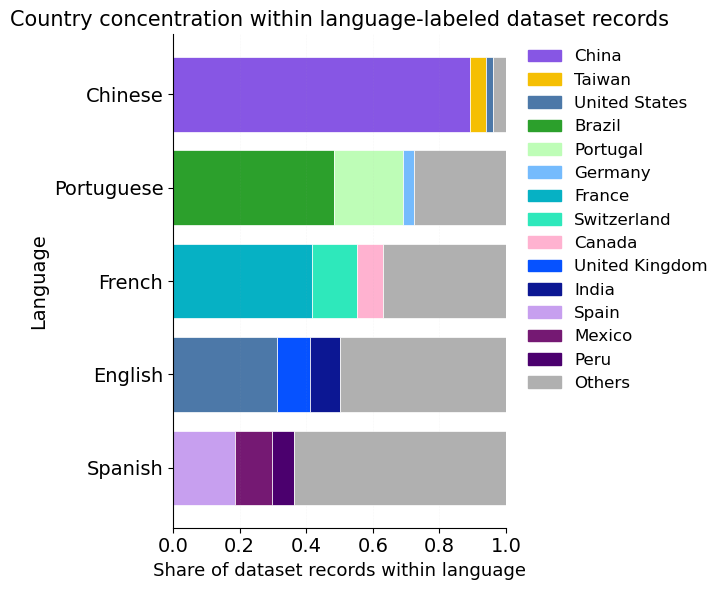

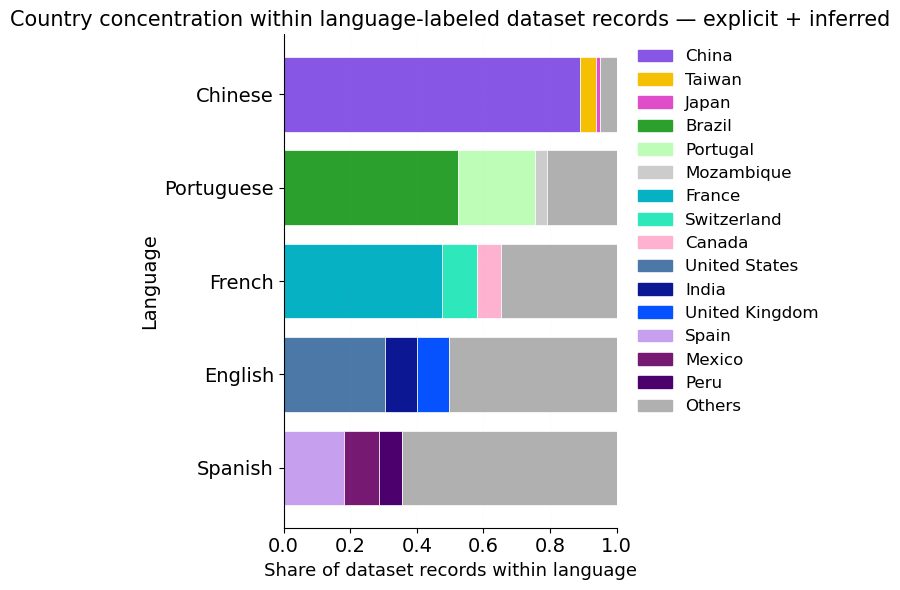

Explicit Figure 5 segment order (highest contributing country first):


,language,country,count,share
0,Chinese,China,272,0.891803
1,Chinese,Taiwan,15,0.049180
2,Chinese,United States,6,0.019672
3,Chinese,Others,12,0.039344
4,Portuguese,Brazil,28,0.482759
5,Portuguese,Portugal,12,0.206897
6,Portuguese,Germany,2,0.034483
7,Portuguese,Others,16,0.275862
8,French,France,59,0.418440
9,French,Switzerland,19,0.134752


In [46]:

LANGUAGE_ORDER = [
    "Chinese",
    "Portuguese",
    "French",
    "English",
    "Spanish",
]

COUNTRY_PALETTE = {
    # English
    "United States": "#4C78A8",
    "China": "#8756e4",
    "India": "#0c1793",
    "United Kingdom": "#0652ff",
    "Germany": "#75bbfd",

    # Spanish
    "Spain": "#c79fef",
    "Mexico": "#751973",
    "Peru": "#4b006e",

    # French
    "France": "#06b1c4",
    "Switzerland": "#2ee8bb",
    "Canada": "#ffb2d0",
    "Belgium": "#b0054b",

    # Portuguese
    "Brazil": "#2CA02C",
    "Portugal": "#befdb7",

    # Arabic
    "Saudi Arabia": "#fc824a",
    "Egypt": "#ffb07c",
    "Qatar": "#875f42",
    "United Arab Emirates": "#875f42",
    "Morocco": "#6c7a0e",
    "Palestine": "#ffff81",

    # Chinese / other recurring top countries
    "Taiwan": "#f5bf03",
    "Japan": "#df4ec8",
    "South Korea": "#e50000",

    "Others": "#B0B0B0",
}

def top3_others_dynamic(counts):
    out = []
    for language in LANGUAGE_ORDER:
        group = counts[counts["language"] == language].copy()
        group = group.sort_values(
            ["count", "content_country"],
            ascending=[False, True],
        )
        if group.empty:
            continue

        total = group["count"].sum()
        top3 = group.head(3)
        others = group.iloc[3:]

        # Segments are intentionally highest -> lowest from left to right.
        for _, row in top3.iterrows():
            out.append({
                "language": language,
                "country": row["content_country"],
                "count": int(row["count"]),
                "share": row["count"] / total,
            })

        if not others.empty:
            out.append({
                "language": language,
                "country": "Others",
                "count": int(others["count"].sum()),
                "share": others["count"].sum() / total,
            })
    return pd.DataFrame(out)

def plot_language_camera_ready(counts, title, stem):
    lang_top3 = top3_others_dynamic(counts)

    fig, ax = plt.subplots(figsize=(7.2, 6))
    y_positions = np.arange(len(LANGUAGE_ORDER))

    for y, language in zip(y_positions, LANGUAGE_ORDER):
        # Preserve descending count order from top3_others_dynamic.
        sub = lang_top3[lang_top3["language"] == language].copy()
        left = 0.0

        for _, row in sub.iterrows():
            country = row["country"]
            share = row["share"]
            color = COUNTRY_PALETTE.get(country, "#CCCCCC")

            ax.barh(
                y,
                share,
                left=left,
                color=color,
                edgecolor="white",
                linewidth=0.5,
            )
            left += share

    ax.set_yticks(y_positions)
    ax.set_yticklabels(LANGUAGE_ORDER)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share of dataset records within language", fontsize=13)
    ax.set_ylabel("Language", fontsize=14)
    ax.set_title(title, fontsize=15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", linestyle="--", linewidth=0.4, alpha=0.1)
    ax.tick_params(axis="both", labelsize=14)

    # Legend follows first appearance in plotted top-3 segments, with Others last.
    legend_countries = []
    for c in lang_top3["country"]:
        if c not in legend_countries and c != "Others":
            legend_countries.append(c)
    if "Others" in set(lang_top3["country"]):
        legend_countries.append("Others")

    handles = [
        plt.Rectangle(
            (0, 0), 1, 1,
            color=COUNTRY_PALETTE.get(c, "#CCCCCC"),
        )
        for c in legend_countries
    ]
    ax.legend(
        handles,
        legend_countries,
        fontsize=12,
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_language_camera_ready(
    lang_country_explicit,
    "Country concentration within language-labeled dataset records",
    "fig5_language_country_explicit_camera_ready",
)
plot_language_camera_ready(
    lang_country_sensitivity,
    "Country concentration within language-labeled dataset records — explicit + inferred",
    "fig5_language_country_explicit_plus_inferred_camera_ready",
)

print("Explicit Figure 5 segment order (highest contributing country first):")
display(top3_others_dynamic(lang_country_explicit))


## 15. Appendix — producer → represented-country Sankey

In [40]:

try:
    import plotly.graph_objects as go

    top_producers = (
        explicit_pc_cross["producer_country"]
        .value_counts()
        .head(5)
        .index
    )
    top_content = (
        explicit_pc_cross["content_country"]
        .value_counts()
        .head(10)
        .index
    )

    sankey_df = explicit_pc_cross.copy()
    sankey_df["content_country_simplified"] = np.where(
        sankey_df["content_country"].isin(top_content),
        sankey_df["content_country"],
        "Other Countries",
    )

    edges = (
        sankey_df
        .groupby(["producer_country", "content_country_simplified"])
        .size()
        .reset_index(name="value")
    )
    edges = edges[edges["producer_country"].isin(top_producers)].copy()
    edges.to_csv(
        OUTPUT_DIR / "producer_represented_sankey_edges_explicit.csv",
        index=False,
    )

    producers = list(top_producers)

    # Stable right-side ordering: largest represented-country totals first,
    # with Other Countries last.
    content_order = (
        edges.groupby("content_country_simplified")["value"]
        .sum()
        .sort_values(ascending=False)
        .index
        .tolist()
    )
    contents = [c for c in content_order if c != "Other Countries"]
    if "Other Countries" in content_order:
        contents.append("Other Countries")

    # Critical fix from the late old-notebook Sankey:
    # producer and represented nodes get distinct INTERNAL IDs even if
    # they share the same visible country name.
    producer_ids = [f"P::{p}" for p in producers]
    content_ids = [f"C::{c}" for c in contents]
    node_ids = producer_ids + content_ids
    labels = producers + contents
    id_to_index = {node_id: i for i, node_id in enumerate(node_ids)}

    producer_node_color_map = {
        "United States": "#4C78A8",
        "China": "#54A24B",
        "Germany": "#F58518",
        "France": "#B279A2",
        "United Kingdom": "#E45756",
    }
    producer_link_color_map = {
        "United States": "rgba(76,120,168,0.28)",
        "China": "rgba(84,162,75,0.28)",
        "Germany": "rgba(245,133,24,0.28)",
        "France": "rgba(178,121,162,0.28)",
        "United Kingdom": "rgba(228,87,86,0.28)",
    }

    producer_colors = [
        producer_node_color_map.get(p, "#4C78A8")
        for p in producers
    ]
    content_colors = [
        "#B0B0B0" if c == "Other Countries" else "#13BBAF"
        for c in contents
    ]

    source, target, value, link_colors = [], [], [], []
    for _, row in edges.iterrows():
        producer = row["producer_country"]
        content = row["content_country_simplified"]

        if producer not in producers or content not in contents:
            continue

        source.append(id_to_index[f"P::{producer}"])
        target.append(id_to_index[f"C::{content}"])
        value.append(int(row["value"]))
        link_colors.append(
            producer_link_color_map.get(
                producer,
                "rgba(120,120,120,0.25)",
            )
        )

    # Fixed left/right placement prevents Plotly from interleaving nodes.
    x_positions = [0.02] * len(producers) + [0.98] * len(contents)

    def spaced_positions(n, top=0.05, bottom=0.95):
        if n <= 1:
            return [0.5]
        step = (bottom - top) / (n - 1)
        return [top + i * step for i in range(n)]

    producer_y = spaced_positions(
        len(producers), top=0.15, bottom=0.79
    )
    # Reverse the right-side vertical direction, matching the late old cell
    # and reducing crossing for the largest flows.
    content_y = spaced_positions(
        len(contents), top=0.79, bottom=0.10
    )
    y_positions = producer_y + content_y

    fig = go.Figure(
        go.Sankey(
            arrangement="fixed",
            node=dict(
                pad=30,
                thickness=10,
                line=dict(
                    color="rgba(80,80,80,0.6)",
                    width=0.5,
                ),
                label=labels,
                color=producer_colors + content_colors,
                x=x_positions,
                y=y_positions,
                hovertemplate="%{label}<extra></extra>",
            ),
            link=dict(
                source=source,
                target=target,
                value=value,
                color=link_colors,
                hovertemplate=(
                    "From %{source.label} to %{target.label}<br>"
                    "%{value} associations<extra></extra>"
                ),
            ),
        )
    )

    fig.add_annotation(
        x=0.01, y=1.03,
        text="Producer countries",
        showarrow=False,
        xanchor="left",
        font=dict(size=14),
    )
    fig.add_annotation(
        x=0.99, y=1.03,
        text="Represented countries",
        showarrow=False,
        xanchor="right",
        font=dict(size=14),
    )
    fig.update_layout(
        title="Dataset Production and Representation Across Countries",
        font=dict(size=12),
        width=950,
        height=460,
        margin=dict(l=40, r=40, t=70, b=20),
    )

    stem = "producer_represented_sankey_explicit_camera_ready"
    fig.write_html(OUTPUT_DIR / f"{stem}.html")
    try:
        fig.write_image(OUTPUT_DIR / f"{stem}.pdf")
        fig.write_image(OUTPUT_DIR / f"{stem}.png", scale=3)
        print("Saved Sankey HTML/PDF/PNG.")
    except Exception as export_error:
        print(
            "Sankey HTML saved; static PDF/PNG export unavailable in "
            f"this runtime: {export_error}"
        )

    fig.show()
except Exception as e:
    print("Sankey skipped:", e)


Saved Sankey HTML/PDF/PNG.


## 16. Submitted paper → rebuttal correction → post-audit dashboard

In [41]:
change_dashboard = pd.DataFrame([
    {
        "metric": "Core / analysis population",
        "submitted": "18,035 unique datasets",
        "rebuttal": "18,035 paper-level dataset records",
        "v2.2 explicit primary": f"{len(eligible):,} primary-eligible; {len(explicit):,} explicit geography",
        "v2.2 sensitivity": f"{len(eligible):,} primary-eligible; {len(explicit_plus_inferred):,} explicit+inferred geography",
    },
    {
        "metric": "Country associations",
        "submitted": "≈21,360",
        "rebuttal": "21,360",
        "v2.2 explicit primary": f"{len(explicit_country):,}",
        "v2.2 sensitivity": f"{len(any_country):,}",
    },
    {
        "metric": "Countries represented",
        "submitted": "191",
        "rebuttal": "191",
        "v2.2 explicit primary": str(int((primary_counts > 0).sum())),
        "v2.2 sensitivity": str(int((sensitivity_counts > 0).sum())),
    },
    {
        "metric": "Top-5 represented share",
        "submitted": "~39%",
        "rebuttal": "38.7%",
        "v2.2 explicit primary": f"{primary_counts.head(5).sum()/primary_counts.sum():.1%}",
        "v2.2 sensitivity": f"{sensitivity_counts.head(5).sum()/sensitivity_counts.sum():.1%}",
    },
    {
        "metric": "Top-10 represented share",
        "submitted": "not foregrounded",
        "rebuttal": "54.0%",
        "v2.2 explicit primary": f"{primary_counts.head(10).sum()/primary_counts.sum():.1%}",
        "v2.2 sensitivity": f"{sensitivity_counts.head(10).sum()/sensitivity_counts.sum():.1%}",
    },
    {
        "metric": "Empty country-task cells",
        "submitted": "59.7%",
        "rebuttal": "59.7% (upper-bound interpretation)",
        "v2.2 explicit primary": f"{country_task_sparsity.loc['explicit','empty_share']:.1%}",
        "v2.2 sensitivity": f"{country_task_sparsity.loc['explicit_plus_inferred','empty_share']:.1%}",
    },
    {
        "metric": "Content × producer associations",
        "submitted": "32,301 after producer correction",
        "rebuttal": "32,301",
        "v2.2 explicit primary": f"{len(explicit_pc_cross):,}",
        "v2.2 sensitivity": f"{len(sensitivity_pc_cross):,}",
    },
    {
        "metric": "Top-10 producer share",
        "submitted": "62.37%",
        "rebuttal": "62.86%",
        "v2.2 explicit primary": f"{producer_cross_compare.loc['Primary: explicit only','top10_producer_share']:.1%}",
        "v2.2 sensitivity": f"{producer_cross_compare.loc['Sensitivity: explicit + inferred','top10_producer_share']:.1%}",
    },
    {
        "metric": "University-count association",
        "submitted": "r≈0.55; ρ≈0.47",
        "rebuttal": "same analysis",
        "v2.2 explicit primary": (
            f"r={infra_stats_df.loc['Primary: explicit only','pearson_loglog_r']:.2f}; "
            f"ρ={infra_stats_df.loc['Primary: explicit only','spearman_rho']:.2f}"
        ),
        "v2.2 sensitivity": (
            f"r={infra_stats_df.loc['Sensitivity: explicit + inferred','pearson_loglog_r']:.2f}; "
            f"ρ={infra_stats_df.loc['Sensitivity: explicit + inferred','spearman_rho']:.2f}"
        ),
    },
])
display(change_dashboard)
change_dashboard.to_csv(OUTPUT_DIR / "paper_rebuttal_v2_2_change_dashboard.csv", index=False)

,metric,submitted,rebuttal,v2.2 explicit primary,v2.2 sensitivity
0,Core / analysis population,"18,035 unique datasets","18,035 paper-level dataset records","13,462 primary-eligible; 2,447 explicit geography","13,462 primary-eligible; 3,506 explicit+inferr..."
1,Country associations,"≈21,360","21,360","4,421","6,001"
2,Countries represented,191,191,158,168
3,Top-5 represented share,~39%,38.7%,36.4%,35.7%
4,Top-10 represented share,not foregrounded,54.0%,48.6%,48.6%
5,Empty country-task cells,59.7%,59.7% (upper-bound interpretation),79.2%,75.0%
6,Content × producer associations,"32,301 after producer correction","32,301","6,532","9,013"
7,Top-10 producer share,62.37%,62.86%,61.1%,61.1%
8,University-count association,r≈0.55; ρ≈0.47,same analysis,r=0.65; ρ=0.61,r=0.70; ρ=0.67



## 17. Reproducibility note

This camera-ready-style notebook contains the recomputed v2.2 analyses **and** restores the late `Analysis Exploration.ipynb` styling used for the paper:

- Figure 1 map: `Blues`, Natural Earth projection, paper sizing;
- Figure 1 scarcity: original blue bucket palette and horizontal layout;
- Figure 2: `Blues` heatmap, task/country ordering and alternating country labels;
- Figure 3: original four-regime palette, hollow low-n points, quadrant labels, and curated spotlight countries;
- Figure 4: original two-panel income/university layout and income palette;
- Figure 5: original country palette, top-3 + Others compression, with each language ordered highest-contributing country → lowest;
- Sankey: distinct producer/represented internal node IDs, fixed left/right placement, producer-colored links.

The final plotting cells save **PDF and PNG**. Plotly figures also save HTML and attempt static PDF/PNG export; if the local Plotly/Kaleido renderer is unavailable, the notebook reports that explicitly.

The temporal specialization transition remains intentionally unrecomputed because the frozen v2.2 inputs do not include a verified publication-year field.
